<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>
<h1 style="font-family:verdana; font-size:26px"><center>~ DAC FindIT! 2026: Face Anti-Spoofing dengan DINOv3 ~</center></h1>
<h3 style="font-family:verdana; font-size:14px; color:gray"><center>Klasifikasi serangan presentasi pada sistem pengenalan wajah</center></h3>
<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# **AntiFaceSpoof**

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Analisis Data Eksploratif**](#3)
4. [**Prapemrosesan dan Augmentasi**](#4)
5. [**Subject-Disjoint Split dan DataLoader**](#5)
6. [**Pemodelan**](#6)
7. [**Inferensi dan Submisi**](#7)
8. [**Pasca-Analisis**](#8)
9. [**Daftar Pustaka**](#9)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pendahuluan <a name="1"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Kompetisi

Sistem pengenalan wajah (*face recognition*) yang digunakan pada berbagai platform digital rentan terhadap serangan presentasi (*presentation attack*), yaitu upaya menembus sistem otentikasi menggunakan media pengganti wajah asli. Serangan ini mencakup penggunaan foto cetak, layar digital, masker silikon, hingga manekin. Pada kompetisi **DAC FindIT! 2026**, peserta ditantang membangun model AI/ML yang mampu membedakan wajah asli dari berbagai metode serangan tersebut.

- **Tugas**: klasifikasi gambar ke dalam 6 kelas
- **Kelas target**: `realperson`, `fake_printed`, `fake_mannequin`, `fake_mask`, `fake_screen`, `fake_unknown`
- **Platform**: Kaggle Notebook, GPU T4 x2

---

## Dataset

*Dataset* terdiri dari dua kategori besar: foto wajah asli (*realperson*) dan foto serangan presentasi yang dibagi menjadi lima jenis. Serangan jenis *printed* menggunakan foto cetak, *screen* mengandalkan layar digital untuk memutar ulang gambar, *mask* menggunakan masker 3D berbahan silikon atau resin, *mannequin* menggunakan kepala manekin, sementara *unknown* mencakup metode serangan yang belum terklasifikasi. Setiap gambar dalam *test set* perlu diklasifikasikan ke salah satu dari keenam kelas ini.

---

## Pendekatan: DINOv3 *Linear Probe* + *Subject-Disjoint Split*

DINOv3 adalah *vision foundation model* hasil pelatihan *self-supervised* Meta AI pada 1,689 miliar gambar (dataset LVD-1689M). Representasi fitur yang dihasilkannya terbukti unggul pada berbagai tugas visi (Simeoni dkk., 2025).

V9 mempertahankan *linear probe* beku (backbone sepenuhnya dibekukan) dari V8, dan memperbarui strategi *subject-disjoint split* menjadi: semua gambar yang termasuk dalam kluster subjek (komponen ukuran >= 2 pada graf kosinus) dipaksa masuk ke *training set*. Kuota val (15%) diisi murni dari *singleton* -- gambar yang tidak memiliki tetangga dalam radius 0.50 -- diurutkan alfabetis maju per kelas. Pendekatan ini terbukti mencapai 17/19 kasus GT yang dipisahkan dengan benar (dibanding 8/19 pada split acak murni).

```
DINOv3 ViT-H+/16 (backbone fully frozen)
    |
    +-- CLS token [1280-dim]          -- identitas global wajah
    +-- mean(patch tokens) [1280-dim] -- tekstur lokal permukaan
         |
         concat [2560-dim]
         |
    Linear(2560, 512) -> GELU -> Dropout(0.3)
         |
    Linear(512, 6) -> prediksi kelas
```

Pembagian subjek menggunakan InsightFace buffalo_l (cosine distance, threshold=0.50). Semua komponen berukuran >= 2 (kluster subjek) dipaksa ke train. Singletons (tanpa tetangga) dikocok secara acak bersemai lalu dipilih 20% pertama per kelas untuk val.

---

## Referensi Utama

- [DSC0118 - DINOv3 Implementation for Image Classification](../ref/DSC0118_Over_Under%2035.5_Notebook.ipynb) -- referensi implementasi DINOv3
- [docs/MODEL_ZOO.md](../docs/MODEL_ZOO.md) -- perbandingan *backbone* dan hipotesis prioritas

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inisialisasi <a name="2"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Environment

In [ ]:
!nvidia-smi

Fri Apr  3 00:44:16 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

> Catatan untuk juri dan panitia: untuk mereproduksi submisi tanpa menjalankan *training* dari awal, cukup tetapkan `Settings.RUN_NAME = 'INFERENCE'`, kemudian jalankan *Run All*.

In [ ]:
import os, platform, sys
print('Python :', sys.version)
print('OS     :', platform.system(), platform.release())
print('CWD    :', os.getcwd())

Python : 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
OS     : Linux 6.6.113+
CWD    : /kaggle/working


---

## Instalasi

Baris berikut memasang seluruh pustaka yang diperlukan pada *notebook* ini. Pustaka *transformers* perlu dipasang dari versi terkini agar kompatibel dengan model DINOv3 yang baru tersedia.

In [ ]:
%pip install -q --upgrade transformers
%pip install -q timm huggingface_hub opencv-python-headless python-dotenv networkx gdown insightface onnxruntime-gpu


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 69.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.2/625.2 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 62.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 439.5/439.5 kB 8.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 252.8/252.8 MB 6.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


---

## Pustaka

Seluruh impor dikelompokkan dalam satu sel agar mudah ditelusuri dan diperbarui. PyTorch digunakan sebagai *framework* utama, *transformers* menyediakan akses ke model DINOv3, sementara *torchvision* menangani *pipeline* augmentasi data.

In [ ]:
import csv
import hashlib
import math
import os
import random
import shutil
import subprocess
import sys
import zipfile
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image, ImageOps
from tqdm import tqdm
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import gdown
from huggingface_hub import login
from transformers import AutoModel
from insightface.app import FaceAnalysis

warnings.filterwarnings('ignore')
print('PyTorch   :', torch.__version__)
print('CUDA      :', torch.version.cuda)
print('Device    :', 'cuda' if torch.cuda.is_available() else 'cpu')

PyTorch   : 2.10.0+cu128
CUDA      : 12.8
Device    : cuda


---

## Seed

Pengaturan *seed* dilakukan pada semua sumber keacakan agar hasil pelatihan dapat direproduksi. Meskipun demikian, operasi berbasis GPU tetap dapat menghasilkan sedikit galat numerik antar eksekusi akibat perbedaan penjadwalan *hardware*.

In [ ]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

---

## Settings

Kelas `Settings` memusatkan seluruh konfigurasi eksperimen: *hyperparameter* pelatihan, jalur data, dan konfigurasi model. V17 menggunakan dataset final `dac-findit-2026-clean` dan tetap mempertahankan `SUBJECT_THRESHOLD` serta `VAL_RATIO` untuk *subject-disjoint split*. Ubah `RUN_NAME` menjadi `'INFERENCE'` untuk melewati *training* dan langsung memuat *checkpoint* terbaik.

In [ ]:
class Settings:
    SEED        = 42

    # Mode (ganti 'INFERENCE' untuk skip training)
    RUN_NAME    = 'dinov3_vith_v17_clean_pipeline'

    # Classes
    CLASS_NAMES = [
        'realperson', 'fake_printed', 'fake_mannequin',
        'fake_mask', 'fake_screen', 'fake_unknown',
    ]
    N_CLASSES   = len(CLASS_NAMES)

    # Model
    MODEL_NAME = 'facebook/dinov3-vith16plus-pretrain-lvd1689m'
    EMBED_DIM  = 1280  # ViT-H+ hidden size
    # DINOv3 uses axial RoPE: handles variable resolution natively.
    # Paper uses 512px for patch-16 evaluation; safe with 48 GB VRAM.
    IMG_SIZE   = (512, 512)
    TRAIN_ATTN_IMPL = 'sdpa'   # faster path for train / val / inference
    XAI_ATTN_IMPL   = 'eager'  # only needed when extracting attention maps

    # Training
    EPOCHS              = 15
    BATCH_SIZE          = 32
    GRAD_ACCUM_STEPS    = 1  # no accumulation; effective batch = BATCH_SIZE

    LR                  = 3e-4
    # BACKBONE_LR       = 1e-5  # V4: partial fine-tune unfrozen blocks
    # HEAD_LR           = 3e-4  # V4: classification head

    WEIGHT_DECAY        = 1e-4
    # LABEL_SMOOTHING   = 0.1   # V4: disabled -- backbone fully frozen
    DROPOUT             = 0.3
    EARLY_STOP_PATIENCE = 10

    SUBJECT_THRESHOLD   = 0.50  # InsightFace cosine distance threshold (buffalo_l)
    VAL_RATIO           = 0.15
    USE_AMP             = True

    # Normalisation (ImageNet stats)
    IMAGENET_MEAN = (0.485, 0.456, 0.406)
    IMAGENET_STD  = (0.229, 0.224, 0.225)

    # DataLoader
    NUM_WORKERS = 2

    # EDA visualisation
    EDA_SAMPLE_COLS   = 5        # columns in per-class sample grid
    EDA_PALETTE_NAME  = 'flare'
    CLASS_DISPLAY_NAMES = [name.replace('fake_', '') for name in CLASS_NAMES]

    # Paths -- train uses clean dataset, test remains the original raw test set.
    _ON_KAGGLE  = Path('/kaggle/input').exists()
    _LOCAL_DATA = Path('../../dataset')
    _CLOUD_DATA = Path('dataset')
    _DATA_ROOT  = (
        Path('/kaggle/input') if _ON_KAGGLE else
        _LOCAL_DATA           if _LOCAL_DATA.exists() else
        _CLOUD_DATA
    )
    RAW_TRAIN_DIR = (
        Path('/kaggle/input/competitions/data-analytics-competition-dac-find-it-2026/train') if _ON_KAGGLE else
        _DATA_ROOT / 'train'
    )
    TEST_DIR  = (
        Path('/kaggle/input/competitions/data-analytics-competition-dac-find-it-2026/test') if _ON_KAGGLE else
        _DATA_ROOT / 'test'
    )
    TRAIN_DIR = (
        Path('/kaggle/input/datasets/zirach/dac-findit-2026/train') if _ON_KAGGLE else
        _DATA_ROOT / 'train_clean'
    )
    META_DIR  = (
        Path('/kaggle/input/datasets/zirach/dac-findit-2026/meta') if _ON_KAGGLE else
        _DATA_ROOT / 'meta'
    )
    _BASE_OUT = (
        Path('/kaggle/working') if _ON_KAGGLE else
        Path('../../output')    if _LOCAL_DATA.exists() else
        Path('output')
    )
    OUTPUT_DIR  = _BASE_OUT / 'dinov3-vith16plus' / RUN_NAME
    CHECKPOINT_PATH = OUTPUT_DIR / f'{RUN_NAME}_best.pth'
    SUBMISSION_CSV  = OUTPUT_DIR / f'submission_{RUN_NAME}.csv'


CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EDA_PALETTE = sns.color_palette(CFG.EDA_PALETTE_NAME, CFG.N_CLASSES)

print(f'TRAIN_DIR  : {CFG.TRAIN_DIR}  exists={CFG.TRAIN_DIR.exists()}')
print(f'TEST_DIR   : {CFG.TEST_DIR}   exists={CFG.TEST_DIR.exists()}')
print(f'META_DIR   : {CFG.META_DIR}   exists={CFG.META_DIR.exists()}')
print(f'RAW_TRAIN  : {CFG.RAW_TRAIN_DIR}  exists={CFG.RAW_TRAIN_DIR.exists()}')
print(f'OUTPUT_DIR : {CFG.OUTPUT_DIR}')

TRAIN_DIR  : /kaggle/input/datasets/datacommunityhmif/dac-findit-2026-clean/train_clean  exists=True
TEST_DIR   : /kaggle/input/datasets/datacommunityhmif/dac-findit-2026/test   exists=True
META_DIR   : /kaggle/input/datasets/datacommunityhmif/dac-findit-2026-clean/meta   exists=True
RAW_TRAIN  : /kaggle/input/datasets/datacommunityhmif/dac-findit-2026/train  exists=True
OUTPUT_DIR : /kaggle/working/dinov3-vith16plus/dinov3_vith_v17_clean_pipeline


---

## Autentikasi Hugging Face

Model DINOv3 diunduh dari Hugging Face Hub dan memerlukan token autentikasi. Prioritas pencarian token:

`HF_TOKEN` dapat diperoleh melalui pranala berikut, pastikan telah login:

https://huggingface.co/settings/tokens

Berikut tahapan pada cell:

1. **Kaggle Secrets** (`HF_TOKEN`) -- saat berjalan di Kaggle
2. **File `.env`** di direktori kerja -- untuk pengembangan lokal
3. **Variabel lingkungan** `HF_TOKEN` -- fallback umum

Untuk pengembangan lokal, isi berkas `.env` dengan `HF_TOKEN=hf_...`.

In [ ]:
if Path('/kaggle/working').exists():
    from kaggle_secrets import UserSecretsClient
    _hf_token = UserSecretsClient().get_secret('HF_TOKEN')
    print('HF token: Kaggle Secrets')
elif Path('.env').exists():
    from dotenv import load_dotenv
    load_dotenv()
    _hf_token = os.getenv('HF_TOKEN', '')
    print('HF token: .env')
else:
    _hf_token = os.getenv('HF_TOKEN', '')
    print('HF token: variabel lingkungan')

if _hf_token:
    login(token=_hf_token)
    print('Login Hugging Face berhasil.')
else:
    print('[WARN] HF_TOKEN tidak ditemukan. Unduhan model mungkin gagal.')

HF token: Kaggle Secrets
Login Hugging Face berhasil.


---

## Unduh Data

Sel berikut mengunduh *dataset* dari Google Drive apabila *dataset* belum tersedia di jalur lokal maupun Kaggle. Proses ini dilewati secara otomatis jika direktori data sudah ada.

In [ ]:
if not CFG.TRAIN_DIR.exists():
    # Ganti URL dengan tautan unduhan dataset kompetisi
    DATA_URL = 'https://drive.google.com/uc?id=1HpQdRgQoRSp-4FRmZIKnYInwbsGI0lHP'
    ZIP_PATH = CFG._BASE_OUT / 'dataset.zip'
    CFG._BASE_OUT.mkdir(parents=True, exist_ok=True)
    gdown.download(DATA_URL, str(ZIP_PATH), quiet=False)
    print(f'Berhasil diunduh ke {ZIP_PATH}')
else:
    ZIP_PATH = None
    print('Dataset sudah tersedia, pengunduhan dilewati.')

Dataset sudah tersedia, pengunduhan dilewati.


---

## Ekstraksi ZIP

Jika dataset diunduh sebagai arsip ZIP, sel ini mengekstraknya ke direktori data. Proses ini dilewati apabila direktori train sudah ada.

In [ ]:
if ZIP_PATH is not None and ZIP_PATH.exists() and not CFG.TRAIN_DIR.exists():
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(CFG._DATA_ROOT)
    print(f'Diekstrak ke {CFG._DATA_ROOT}')
else:
    print('Ekstraksi dilewati.')

Ekstraksi dilewati.


---

## Persiapan Direktori

Notebook ini memisahkan dua kebutuhan data:

- **EDA dan verifikasi SHA256** menggunakan `raw train/test`
- **training dan validasi model** menggunakan `train_clean`

Dengan begitu, bagian analisis tetap merefleksikan kondisi mentah dataset, sementara eksperimen model tetap berjalan di dataset yang sudah dibersihkan.

In [ ]:
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

def list_images(root_dir):
    root_dir = Path(root_dir)
    if not root_dir.exists():
        return []
    return sorted(
        [p for p in root_dir.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES],
        key=lambda p: p.name.lower(),
    )

def build_pairs(root_dir, class_names):
    pairs = []
    for idx, cls in enumerate(class_names):
        cls_dir = Path(root_dir) / cls
        if not cls_dir.exists():
            print(f'  [WARN] tidak ditemukan: {cls_dir}')
            continue
        for p in list_images(cls_dir):
            pairs.append((p, idx))
    return pairs

def load_rgb_image(path):
    """Load image with EXIF correction. RandomRotate90 covers all orientations
    during training; 8-view D4 TTA covers all orientations at inference.
    """
    return ImageOps.exif_transpose(Image.open(path).convert('RGB'))

raw_train_pairs = build_pairs(CFG.RAW_TRAIN_DIR, CFG.CLASS_NAMES) if CFG.RAW_TRAIN_DIR.exists() else []
train_pairs = build_pairs(CFG.TRAIN_DIR, CFG.CLASS_NAMES)
test_images = list_images(CFG.TEST_DIR)
test_id_lookup = {p.stem: p.name for p in test_images}

print(f'Pasangan raw train   : {len(raw_train_pairs)}')
print(f'Pasangan train_clean : {len(train_pairs)}')
print(f'Gambar test          : {len(test_images)}')
for idx, cls in enumerate(CFG.CLASS_NAMES):
    n_raw = sum(1 for _, i in raw_train_pairs if i == idx)
    n_clean = sum(1 for _, i in train_pairs if i == idx)
    print(f'  {cls:20s}: raw={n_raw:<4d} clean={n_clean}')

Pasangan raw train   : 1652
Pasangan train_clean : 1471
Gambar test          : 404
  realperson          : raw=465  clean=400
  fake_printed        : raw=118  clean=107
  fake_mannequin      : raw=224  clean=194
  fake_mask           : raw=278  clean=259
  fake_screen         : raw=229  clean=191
  fake_unknown        : raw=338  clean=320


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Analisis Data Eksploratif <a name="3"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian EDA menggunakan **raw train/test** agar pola distribusi, variasi resolusi, dan contoh visual masih merefleksikan kondisi mentah dataset sebelum pembersihan.

---

## Distribusi Kelas

Ketidakseimbangan kelas (*class imbalance*) yang signifikan akan memengaruhi pemilihan fungsi *loss* dan strategi *sampling* pada tahap pelatihan. Visualisasi berikut menunjukkan jumlah sampel di setiap kelas pada **raw train set**.

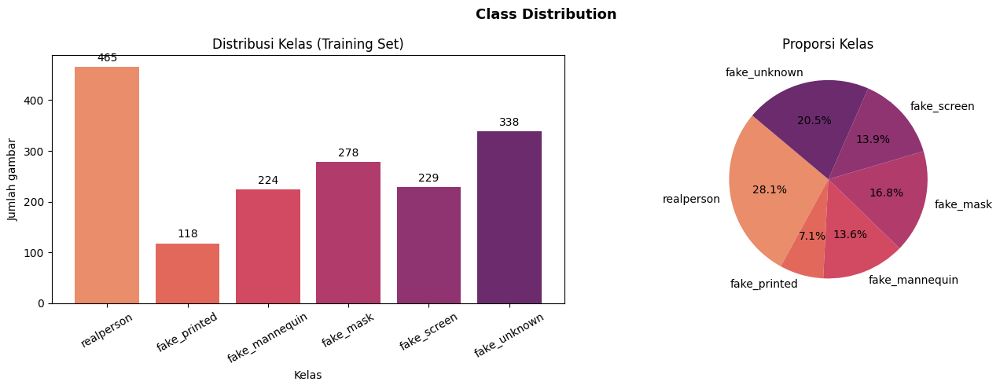

Total raw training : 1652
Rasio maks/min : 3.94x


In [ ]:
class_counts = Counter(i for _, i in raw_train_pairs)
labels = [CFG.CLASS_NAMES[i] for i in sorted(class_counts)]
values = [class_counts[i] for i in sorted(class_counts)]
total  = sum(values)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bars = ax1.bar(labels, values, color=EDA_PALETTE)
ax1.bar_label(bars, padding=3)
ax1.set_xlabel('Kelas')
ax1.set_ylabel('Jumlah gambar')
ax1.set_title('Distribusi Kelas (Training Set)')
ax1.tick_params(axis='x', rotation=30)

ax2.pie(values, labels=labels, colors=EDA_PALETTE, autopct='%1.1f%%', startangle=140)
ax2.set_title('Proporsi Kelas')

fig.suptitle('Class Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '01_class_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Total raw training : {total}')
print(f'Rasio maks/min : {max(values)/min(values):.2f}x')

> ### Insights
> Distribusi kelas menentukan apakah diperlukan *class weighting* atau *oversampling* > pada pelatihan. Rasio ketidakseimbangan di atas 3x umumnya cukup untuk memengaruhi > metrik *macro F1* secara signifikan. Apabila rasio tersebut terdeteksi, > `class_weight='balanced'` atau `WeightedRandomSampler` perlu dipertimbangkan.

---

## Sampel Gambar per Kelas

Visualisasi sampel dari setiap kelas membantu memahami perbedaan visual antar jenis serangan. Perbedaan tekstur permukaan, pencahayaan, dan artefak kamera merupakan petunjuk utama yang perlu dibedakan oleh *patch token* DINOv3.

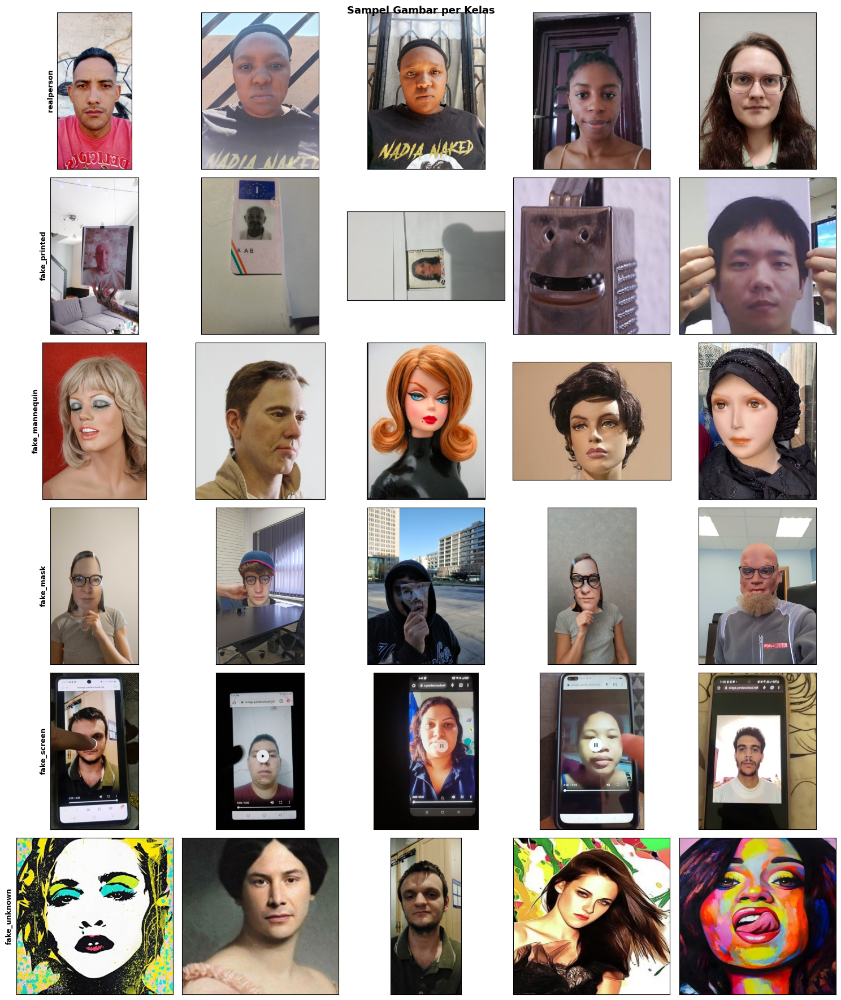

In [ ]:
fig, axes = plt.subplots(CFG.N_CLASSES, CFG.EDA_SAMPLE_COLS,
                         figsize=(CFG.EDA_SAMPLE_COLS * 3, CFG.N_CLASSES * 3))

for row, cls_name in enumerate(CFG.CLASS_NAMES):
    cls_pairs = [(p, i) for p, i in raw_train_pairs if i == row]
    samples   = random.sample(cls_pairs, min(CFG.EDA_SAMPLE_COLS, len(cls_pairs)))
    for col in range(CFG.EDA_SAMPLE_COLS):
        ax = axes[row, col]
        if col < len(samples):
            img_path, label_idx = samples[col]
            img = load_rgb_image(img_path)
            ax.imshow(img)
            if col == 0:
                ax.set_ylabel(cls_name, fontsize=9, fontweight='bold')
        else:
            ax.axis('off')
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle('Sampel Gambar per Kelas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '02_class_samples.png', dpi=100, bbox_inches='tight')
plt.show()

> ### Insights
> Perhatikan apakah serangan *fake_mask* secara visual menyerupai *realperson*, > karena keduanya merupakan pasangan tersulit berdasarkan hipotesis dalam `docs/MODEL_ZOO.md`. > Perbedaan tekstur permukaan (kulit organik vs. silikon) adalah fitur diskriminatif > yang paling menentukan performa model pada pasangan kelas ini.

---

## Distribusi Resolusi Gambar

Variasi resolusi dan *aspect ratio* antar gambar berpengaruh pada strategi *resizing* dalam *pipeline* pemrosesan. Gambar dengan resolusi terlalu rendah berisiko kehilangan detail tekstur yang kritis untuk membedakan kelas serangan.

Membaca dimensi gambar: 100%|██████████| 500/500 [00:17<00:00, 28.84it/s]


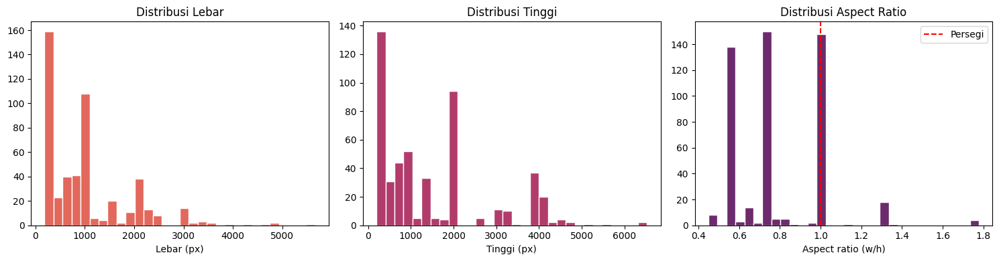

Lebar  -- min: 187 | mean: 1038 | max: 5664
Tinggi -- min: 194 | mean: 1492 | max: 6528


In [ ]:
widths, heights = [], []
sample_for_res = random.sample(raw_train_pairs, min(500, len(raw_train_pairs))) if raw_train_pairs else []

for p, label_idx in tqdm(sample_for_res, desc='Membaca dimensi gambar'):
    img = load_rgb_image(p)
    w, h = img.size
    widths.append(w)
    heights.append(h)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(widths,  bins=30, color=EDA_PALETTE[1], edgecolor='white')
axes[0].set_xlabel('Lebar (px)')
axes[0].set_title('Distribusi Lebar')

axes[1].hist(heights, bins=30, color=EDA_PALETTE[3], edgecolor='white')
axes[1].set_xlabel('Tinggi (px)')
axes[1].set_title('Distribusi Tinggi')

ar = [w/h for w, h in zip(widths, heights)]
axes[2].hist(ar, bins=30, color=EDA_PALETTE[5], edgecolor='white')
axes[2].axvline(1.0, color='red', linestyle='--', label='Persegi')
axes[2].set_xlabel('Aspect ratio (w/h)')
axes[2].set_title('Distribusi Aspect Ratio')
axes[2].legend()

plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '03_resolution.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Lebar  -- min: {min(widths)} | mean: {np.mean(widths):.0f} | max: {max(widths)}')
print(f'Tinggi -- min: {min(heights)} | mean: {np.mean(heights):.0f} | max: {max(heights)}')

> ### Insights
> Jika mayoritas gambar sudah mendekati persegi (*aspect ratio* mendekati 1.0), > strategi `Resize` langsung ke `IMG_SIZE` lebih aman daripada `RandomResizedCrop` agresif. > Gambar dengan resolusi di bawah 112x112 perlu diperiksa secara manual karena > tekstur anti-*spoofing* kemungkinan tidak terpreservasi dengan baik.

---

## Pengecekan Duplikat

Bagian ini menghitung ulang **exact duplicate** berbasis SHA256 pada **raw train/test**. Tujuannya adalah memperlihatkan distribusi grup duplikat, overlap train-test, dan graf grup terbesar sebelum proses deduplikasi maupun relabel manual dijalankan.

In [ ]:
SHA256_COLORS = {
    'realperson': '#2e86de',
    'fake_printed': '#e67e22',
    'fake_mannequin': '#8e44ad',
    'fake_mask': '#16a085',
    'fake_screen': '#c0392b',
    'fake_unknown': '#7f8c8d',
    'test': '#f1c40f',
}

def sha256_file(path, chunk_size=1024 * 1024):
    hasher = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            hasher.update(chunk)
    return hasher.hexdigest()

sha_train_records = [
    {'filename': p.name, 'label': CFG.CLASS_NAMES[i], 'path': p, 'source': 'train'}
    for p, i in raw_train_pairs
]
sha_test_records = [
    {'filename': p.name, 'label': '', 'path': p, 'source': 'test'}
    for p in test_images
]
sha_records = sha_train_records + sha_test_records
df_sha = pd.DataFrame([
    {'filename': rec['filename'], 'label': rec['label'], 'source': rec['source'],
     'sha256': sha256_file(rec['path'])}
    for rec in tqdm(sha_records, desc='SHA256 raw files')
])
df_sha['node'] = df_sha['source'] + '::' + df_sha['filename']
df_sha['group_size'] = df_sha.groupby('sha256')['filename'].transform('size')
df_sha_dups = df_sha[df_sha['group_size'] > 1].copy()
df_sha_groups = (
    df_sha.groupby('sha256')
    .agg(
        size=('filename', 'size'),
        n_train=('source', lambda s: int((s == 'train').sum())),
        n_test=('source', lambda s: int((s == 'test').sum())),
        train_labels=('label', lambda s: '|'.join(sorted({x for x in s if x}))),
        members=('node', lambda s: '|'.join(sorted(s))),
    )
    .reset_index()
)
df_sha_groups = df_sha_groups[df_sha_groups['size'] > 1].copy()
df_sha_groups['has_train_test_overlap'] = ((df_sha_groups['n_train'] > 0) & (df_sha_groups['n_test'] > 0)).astype(int)
df_sha_groups['n_train_labels'] = df_sha_groups['train_labels'].map(lambda x: 0 if not x else len(x.split('|')))
df_sha_groups['is_mixed_train_label'] = (df_sha_groups['n_train_labels'] > 1).astype(int)
print(f'Total raw train images         : {len(sha_train_records)}')
print(f'Total raw test images          : {len(sha_test_records)}')
print(f'Exact duplicate groups         : {len(df_sha_groups)}')
print(f'Images in duplicate groups     : {len(df_sha_dups)}')
print(f"Train-test overlap groups      : {int(df_sha_groups['has_train_test_overlap'].sum()) if not df_sha_groups.empty else 0}")
display(df_sha_groups.sort_values(['size', 'has_train_test_overlap'], ascending=[False, False]).head(10))

SHA256 raw files: 100%|██████████| 2056/2056 [00:20<00:00, 101.76it/s]


Total raw train images         : 1652
Total raw test images          : 404
Exact duplicate groups         : 235
Images in duplicate groups     : 507
Train-test overlap groups      : 87


,sha256,size,n_train,n_test,train_labels,members,has_train_test_overlap,n_train_labels,is_mixed_train_label
288,26ae8cd71ff2d012d33a024559dd81ec2332d07f3dc32c...,5,4,1,fake_mannequin|fake_mask|fake_printed,test::test_362.jpg|train::mannequin_146.jpg|tr...,1,3,1
47,077d7c4f1927d51d0de0c93ad8fc4ea32026a0ac7c3f48...,4,3,1,realperson,test::test_139.jpg|train::real_088.jpg|train::...,1,1,0
671,5cc83b5b64f95d859f988c15e0bc180817de4af935a144...,4,2,2,fake_mannequin|fake_screen,test::test_251.jpg|test::test_404.jpg|train::m...,1,2,1
705,61d860ec71c1e47c74da540f88c70902597150d2c307f6...,4,3,1,fake_mannequin|fake_mask|fake_unknown,test::test_011.jpg|train::mannequin_192.jpg|tr...,1,3,1
1770,fdbcfc688b6313387dcaa4c06073664c1dc381bb56ca31...,4,3,1,fake_mask|fake_printed|fake_unknown,test::test_154.jpg|train::mask_193.jpg|train::...,1,3,1
1445,cdad40cd30d99314355a4d97799449c83405e1fd991715...,4,4,0,fake_mask|fake_unknown,train::mask_122.jpg|train::mask_270.jpg|train:...,0,2,1
122,0f327fafc6e8598b014c635e97e70ce2e36844851a4fd6...,3,2,1,fake_mannequin|fake_screen,test::test_366.jpg|train::mannequin_111.jpg|tr...,1,2,1
143,11fb55119b0faece5702eb7578e547884eafe6a1d0421a...,3,2,1,fake_mannequin|fake_screen,test::test_220.jpg|train::mannequin_042.jpg|tr...,1,2,1
285,2613c36ba1f3f62ba678cd76ef73536def66cc114a0732...,3,2,1,fake_mannequin|fake_screen,test::test_183.jpg|train::mannequin_005.jpg|tr...,1,2,1
328,2c84b18f8b88a2c14218e743549a9667b26fe2491aa61b...,3,2,1,fake_mannequin|fake_screen,test::test_138.jpg|train::mannequin_116.jpg|tr...,1,2,1


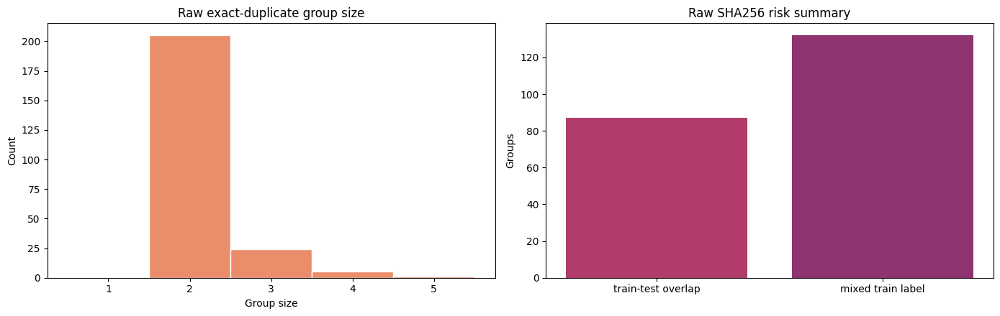

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dup_sizes = df_sha_groups['size'].to_numpy() if not df_sha_groups.empty else np.array([])
if len(dup_sizes):
    bins = np.arange(0.5, dup_sizes.max() + 1.5, 1.0)
    axes[0].hist(dup_sizes, bins=bins, color=EDA_PALETTE[0], edgecolor='white')
axes[0].set_title('Raw exact-duplicate group size')
axes[0].set_xlabel('Group size')
axes[0].set_ylabel('Count')
overlap_counts = [
    int((df_sha_groups['has_train_test_overlap'] == 1).sum()) if not df_sha_groups.empty else 0,
    int((df_sha_groups['is_mixed_train_label'] == 1).sum()) if not df_sha_groups.empty else 0,
]
axes[1].bar(['train-test overlap', 'mixed train label'], overlap_counts, color=[EDA_PALETTE[3], EDA_PALETTE[4]])
axes[1].set_title('Raw SHA256 risk summary')
axes[1].set_ylabel('Groups')
plt.tight_layout()
plt.show()

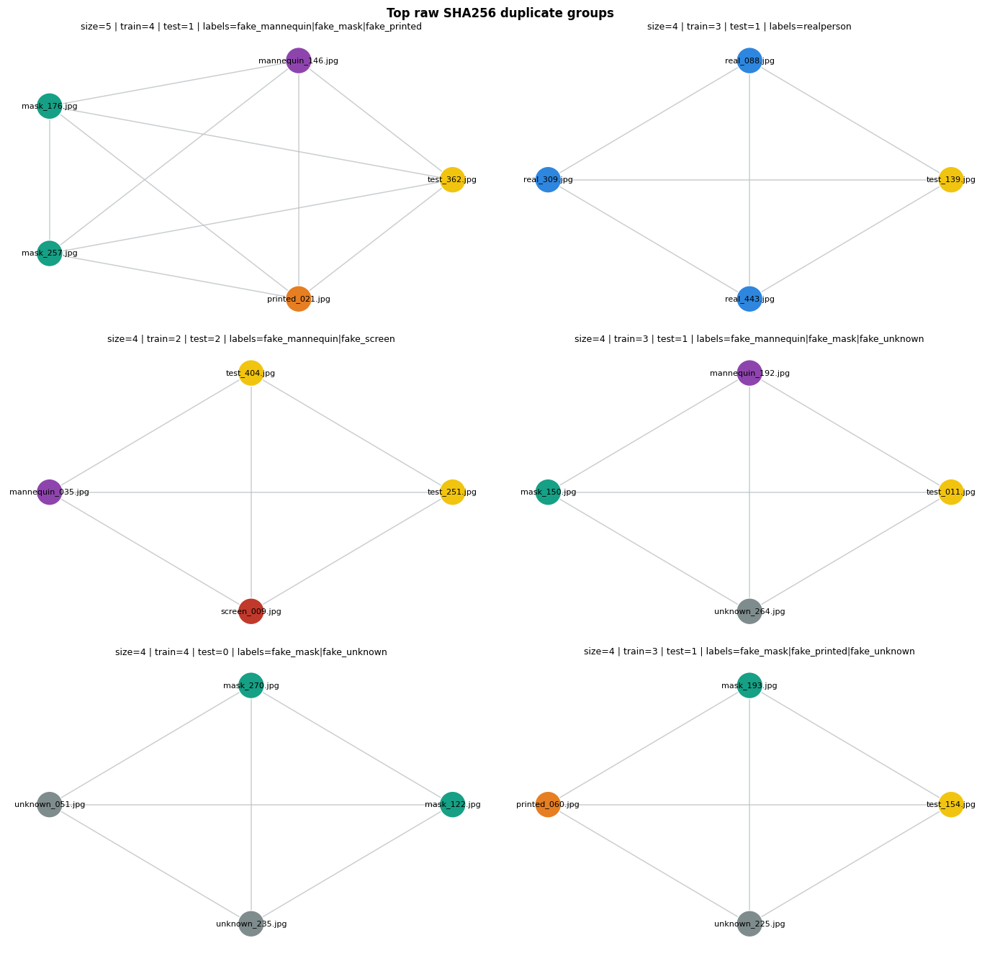

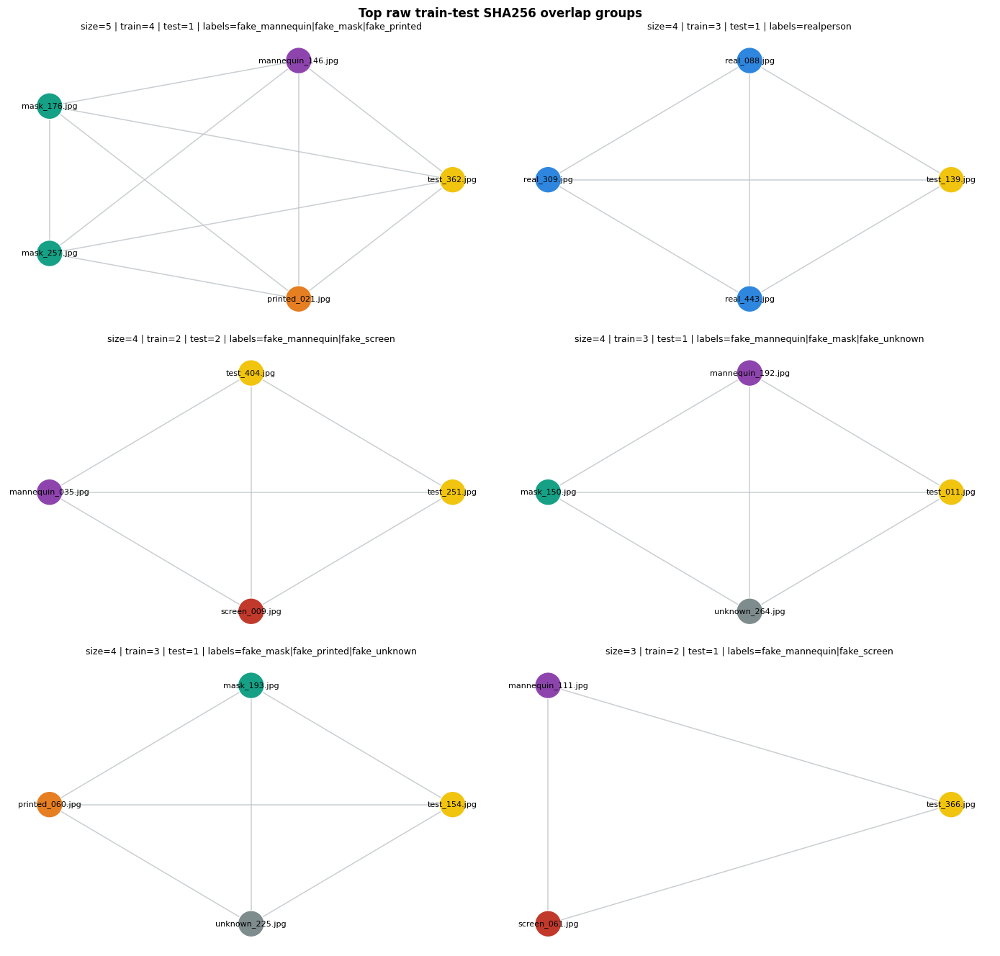

In [ ]:
def draw_sha256_groups(groups_df, df_members, title, top_n=6):
    if groups_df.empty:
        print('No groups to plot.')
        return
    plot_df = groups_df.sort_values(['size', 'sha256'], ascending=[False, True]).head(top_n)
    ncols = 2 if len(plot_df) > 1 else 1
    nrows = int(np.ceil(len(plot_df) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, max(4.5, nrows * 4.5)))
    axes = np.atleast_1d(axes).reshape(-1)
    node_label_lookup = df_members.set_index('node')['label'].to_dict()
    for ax, row in zip(axes, plot_df.itertuples(index=False)):
        members = row.members.split('|')
        G = nx.complete_graph(members)
        pos = nx.circular_layout(G)
        colors = []
        labels = {}
        for node in G.nodes():
            src, fname = node.split('::', 1)
            key = 'test' if src == 'test' else node_label_lookup.get(node, '')
            colors.append(SHA256_COLORS.get(key, '#34495e'))
            labels[node] = fname[:18]
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bdc3c7', width=1.1, alpha=0.8)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=700, edgecolors='white', linewidths=1.0)
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=8, ax=ax)
        ax.set_title(f'size={int(row.size)} | train={int(row.n_train)} | test={int(row.n_test)} | labels={row.train_labels or "-"}', fontsize=9)
        ax.axis('off')
    for ax in axes[len(plot_df):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

draw_sha256_groups(df_sha_groups, df_sha, 'Top raw SHA256 duplicate groups')
draw_sha256_groups(df_sha_groups[df_sha_groups['has_train_test_overlap'] == 1], df_sha, 'Top raw train-test SHA256 overlap groups')

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Prapemrosesan dan Augmentasi <a name="4"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Bagian ini mengeksekusi metadata pembersihan dataset secara bertahap: **raw -> train_deduplicate -> train_clean**. Setelah itu, augmentasi training diterapkan pada dataset akhir yang sudah dibersihkan.

## Penanganan Duplikat

`true_label_duplicate.csv` dieksekusi untuk membentuk `train_deduplicate`: satu file kanonik dipertahankan per grup duplikat, lalu diletakkan pada label hasil kurasi.

In [ ]:
duplicate_csv = CFG.META_DIR / 'true_label_duplicate.csv'
manual_csv    = CFG.META_DIR / 'true_label_manual.csv'

raw_df = pd.DataFrame(
    [{'filename': p.name, 'path': p, 'original_label': CFG.CLASS_NAMES[i]} for p, i in raw_train_pairs]
)
raw_df['filename_norm'] = raw_df['filename'].str.strip().str.lower()

if raw_df['filename_norm'].duplicated().any():
    dup_norms = raw_df.loc[raw_df['filename_norm'].duplicated(), 'filename_norm'].tolist()
    raise RuntimeError(f'Duplicate normalized raw filenames detected: {dup_norms[:5]}')

raw_lookup = raw_df.set_index('filename_norm')[['filename', 'original_label']].to_dict(orient='index')

df_dup_meta = pd.read_csv(duplicate_csv) if duplicate_csv.exists() else pd.DataFrame()

dup_rows = []
reviewed_members = set()
for row in tqdm(df_dup_meta.itertuples(index=False), total=len(df_dup_meta), desc='Resolving duplicate groups'):
    keys    = [Path(str(m).strip()).name.lower() for m in str(row.members).split('|') if m]
    members = [raw_lookup[k]['filename'] for k in keys]
    target  = str(row.selected_true_label)
    if not members:
        continue
    canonical = min(members, key=lambda n: (0 if raw_lookup[n.strip().lower()]['original_label'] == target else 1, n.lower()))
    dup_rows.append({
        'filename': canonical,
        'label': target,
        'original_label': raw_lookup[canonical.strip().lower()]['original_label'],
        'source': 'duplicate_group',
        'group_id': int(row.group_id),
    })
    reviewed_members.update(members)

singletons = (
    raw_df[~raw_df['filename'].isin(reviewed_members)]
    .assign(label=lambda d: d['original_label'], source='singleton', group_id=-1)
    [['filename', 'label', 'original_label', 'source', 'group_id']]
    .to_dict(orient='records')
)

df_train_deduplicate = (
    pd.DataFrame(dup_rows + singletons)
    .sort_values(['label', 'filename'])
    .reset_index(drop=True)
)
print(f'Raw train images        : {len(raw_df)}')
print(f'train_deduplicate       : {len(df_train_deduplicate)}')
print(f'Dropped exact duplicates: {len(raw_df) - len(df_train_deduplicate)}')
display(df_train_deduplicate.head(10))

Resolving duplicate groups: 100%|██████████| 162/162 [00:00<00:00, 80193.23it/s]

Raw train images        : 1652
train_deduplicate       : 1471
Dropped exact duplicates: 181


,filename,label,original_label,source,group_id
0,mannequin_001.jpg,fake_mannequin,fake_mannequin,singleton,-1
1,mannequin_002.jpg,fake_mannequin,fake_mannequin,singleton,-1
2,mannequin_003.jpg,fake_mannequin,fake_mannequin,singleton,-1
3,mannequin_004.jpg,fake_mannequin,fake_mannequin,singleton,-1
4,mannequin_005.jpg,fake_mannequin,fake_mannequin,duplicate_group,50
5,mannequin_006.jpeg,fake_mannequin,fake_mannequin,duplicate_group,74
6,mannequin_007.jpg,fake_mannequin,fake_mannequin,singleton,-1
7,mannequin_008.jpg,fake_mannequin,fake_mannequin,duplicate_group,141
8,mannequin_009.jpg,fake_mannequin,fake_mannequin,singleton,-1
9,mannequin_010.jpg,fake_mannequin,fake_mannequin,singleton,-1


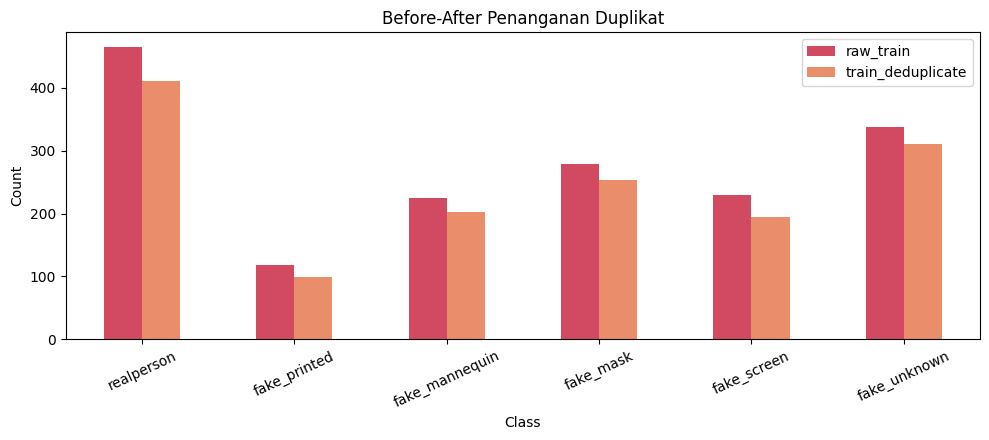

In [ ]:
raw_counts_plot = raw_df['original_label'].value_counts().reindex(CFG.CLASS_NAMES, fill_value=0)
dedup_counts_plot = df_train_deduplicate['label'].value_counts().reindex(CFG.CLASS_NAMES, fill_value=0)
plot_df = pd.DataFrame({'raw_train': raw_counts_plot, 'train_deduplicate': dedup_counts_plot})
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df.plot(kind='bar', ax=ax, color=[EDA_PALETTE[2], EDA_PALETTE[0]])
ax.set_title('Before-After Penanganan Duplikat')
ax.set_ylabel('Count')
ax.set_xlabel('Class')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

---

## Relabel

`true_label_manual.csv` dieksekusi di atas hasil deduplikasi untuk membentuk `train_clean`. Tahap ini hanya mengubah label file-file tertentu yang lolos dedup tetapi masih terindikasi salah label secara individual.

In [ ]:
df_manual_meta = pd.read_csv(manual_csv) if manual_csv.exists() else pd.DataFrame(columns=['filename', 'original_label', 'corrected_label', 'note'])
manual_map = dict(zip(df_manual_meta['filename'].str.strip().str.lower(), df_manual_meta['corrected_label'])) if not df_manual_meta.empty else {}
df_train_clean_rebuilt = df_train_deduplicate.copy()
df_train_clean_rebuilt['dedup_label'] = df_train_clean_rebuilt['label']
df_train_clean_rebuilt['filename_norm'] = df_train_clean_rebuilt['filename'].str.strip().str.lower()
df_train_clean_rebuilt['label'] = df_train_clean_rebuilt['filename_norm'].map(manual_map).fillna(df_train_clean_rebuilt['label'])
df_train_clean = pd.DataFrame([
    {'filename': p.name, 'label': CFG.CLASS_NAMES[i], 'path': p}
    for p, i in train_pairs
]).sort_values(['label', 'filename']).reset_index(drop=True)
rebuilt_counts = df_train_clean_rebuilt['label'].value_counts().reindex(CFG.CLASS_NAMES, fill_value=0)
clean_counts = df_train_clean['label'].value_counts().reindex(CFG.CLASS_NAMES, fill_value=0)
print(f'Manual relabel rows      : {len(df_manual_meta)}')
print(f'Rebuilt train_clean      : {len(df_train_clean_rebuilt)}')
print(f'Loaded train_clean files : {len(df_train_clean)}')
print(f'Count match with input   : {rebuilt_counts.equals(clean_counts)}')
display(df_manual_meta.head(10))
display(df_train_clean_rebuilt[df_train_clean_rebuilt['filename_norm'].isin(manual_map)].head(10))

Manual relabel rows      : 52
Rebuilt train_clean      : 1471
Loaded train_clean files : 1471
Count match with input   : True


,filename,original_label,corrected_label,note
0,mannequin_218.jpg,fake_mannequin,fake_mask,NaN
1,mannequin_191.jpg,fake_mannequin,fake_mask,NaN
2,mannequin_171.jpg,fake_mannequin,fake_unknown,NaN
3,mannequin_158.jpg,fake_mannequin,fake_mask,NaN
4,mannequin_119.jpg,fake_mannequin,fake_mask,NaN
5,mannequin_051.jpg,fake_mannequin,fake_mask,NaN
6,mannequin_047.jpg,fake_mannequin,fake_printed,NaN
7,mannequin_024.jpg,fake_mannequin,fake_unknown,NaN
8,mannequin_009.jpg,fake_mannequin,fake_unknown,NaN
9,mannequin_007.jpg,fake_mannequin,fake_mask,NaN


,filename,label,original_label,source,group_id,dedup_label,filename_norm
1,mannequin_002.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_002.jpg
6,mannequin_007.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_007.jpg
8,mannequin_009.jpg,fake_unknown,fake_mannequin,singleton,-1,fake_mannequin,mannequin_009.jpg
12,mannequin_013.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_013.jpg
22,mannequin_024.jpg,fake_unknown,fake_mannequin,duplicate_group,4,fake_mannequin,mannequin_024.jpg
44,mannequin_047.jpg,fake_printed,fake_mannequin,singleton,-1,fake_mannequin,mannequin_047.jpg
48,mannequin_051.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_051.jpg
111,mannequin_119.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_119.jpg
142,mannequin_158.jpg,fake_mask,fake_mannequin,singleton,-1,fake_mannequin,mannequin_158.jpg
154,mannequin_171.jpg,fake_unknown,fake_mannequin,singleton,-1,fake_mannequin,mannequin_171.jpg


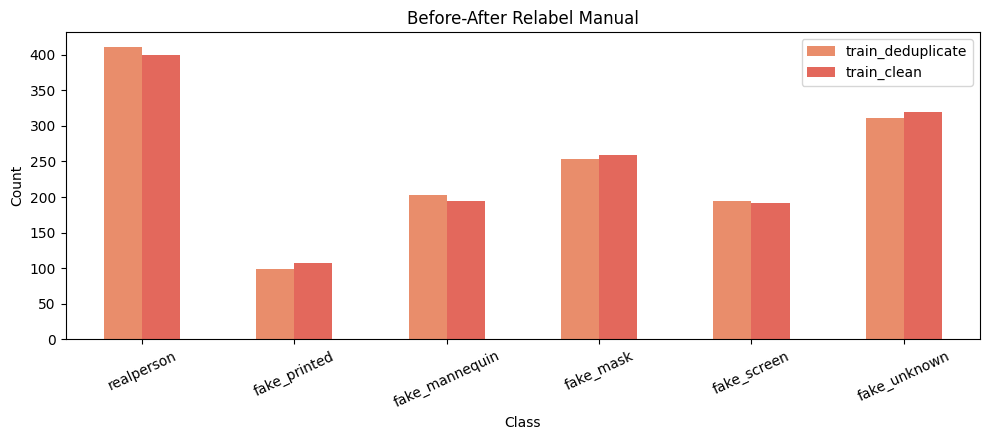

In [ ]:
relabel_counts_plot = df_train_clean_rebuilt['label'].value_counts().reindex(CFG.CLASS_NAMES, fill_value=0)
plot_df = pd.DataFrame({
    'train_deduplicate': dedup_counts_plot,
    'train_clean': relabel_counts_plot,
})
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df.plot(kind='bar', ax=ax, color=[EDA_PALETTE[0], EDA_PALETTE[1]])
ax.set_title('Before-After Relabel Manual')
ax.set_ylabel('Count')
ax.set_xlabel('Class')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
rebuilt_clean_check = df_train_clean_rebuilt[['filename', 'label']].sort_values(['filename', 'label']).reset_index(drop=True)
loaded_clean_check = df_train_clean[['filename', 'label']].sort_values(['filename', 'label']).reset_index(drop=True)
pd.testing.assert_frame_equal(rebuilt_clean_check, loaded_clean_check)
print('OK: rebuilt clean metadata matches loaded train_clean input exactly.')

OK: rebuilt clean metadata matches loaded train_clean input exactly.


In [ ]:
label_to_idx = {name: idx for idx, name in enumerate(CFG.CLASS_NAMES)}
train_pairs = [(Path(row.path), label_to_idx[row.label]) for row in df_train_clean.itertuples(index=False)]
print(f'train_pairs rebuilt from df_train_clean: {len(train_pairs)}')

train_pairs rebuilt from df_train_clean: 1471


## Justifikasi Augmentasi

Dua augmentasi geometri dipilih berdasarkan analisis distribusi orientasi dataset:

- **`RandomHorizontalFlip`** - wajah simetris kiri-kanan; tidak mengubah tekstur permukaan
- **`RandomRotate90`** - variasi orientasi kamera bersifat diskret (kelipatan 90 deg, bukan tilt +/-30 deg); rotasi kontinu akan mengintroduksi artefak interpolasi yang merusak tekstur halus. `RandomVerticalFlip` tidak diperlukan karena sudah dicakup oleh kombinasi Rotate180 + HFlip (D4)

Transformasi yang sengaja dihindari: `RandomResizedCrop` (membuang tepi kertas pada `fake_printed` yang merupakan sinyal diskriminatif), `ColorJitter` (warna relevan untuk deteksi *screen* vs *printed*), `GaussianBlur` (menghapus detail tekstur).

---

## Transformasi Training

In [ ]:
class RandomRotate90:
    """Randomly rotate image by 0 deg, 90 deg, 180 deg, or 270 deg."""
    def __call__(self, img):
        k = random.randint(0, 3)
        return v2.functional.rotate(img, 90 * k) if k > 0 else img


In [ ]:
train_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(CFG.IMG_SIZE, antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    RandomRotate90(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
])

---

## Transformasi Validasi dan Inferensi

In [ ]:
val_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(CFG.IMG_SIZE, antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=CFG.IMAGENET_MEAN, std=CFG.IMAGENET_STD),
])

---

## Visualisasi Augmentasi

Gambar asli ditampilkan bersama tiga varian augmentasi untuk memverifikasi bahwa transformasi geometri tidak merusak tekstur permukaan yang menjadi sinyal utama anti-spoofing.

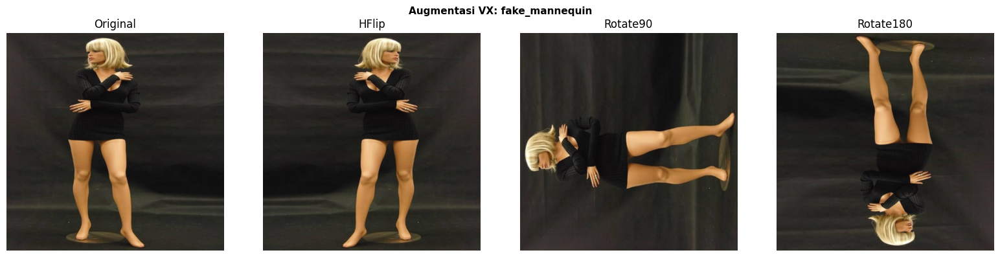

In [ ]:
sample_path, sample_label = train_pairs[0]
orig_img = load_rgb_image(sample_path)

_to_tensor = v2.Compose([
    v2.ToImage(),
    v2.Resize(CFG.IMG_SIZE, antialias=True),
    v2.ToDtype(torch.uint8),
])
orig_t  = _to_tensor(orig_img)
hflip_t = v2.functional.horizontal_flip(orig_t)
rot90_t = v2.functional.rotate(orig_t, 90)
rot180_t = v2.functional.rotate(orig_t, 180)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, img, title in zip(axes,
        [orig_t, hflip_t, rot90_t, rot180_t],
        ['Original', 'HFlip', 'Rotate90', 'Rotate180']):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis('off')

fig.suptitle(
    f'Augmentasi VX: {CFG.CLASS_NAMES[sample_label]}', fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '04_augmentation_vis.png', dpi=100, bbox_inches='tight')
plt.show()

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Subject-Disjoint Split dan DataLoader <a name="5"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Split subjek dilakukan pada **train_clean** yang sudah melalui deduplikasi dan relabel. InsightFace digunakan untuk membangun graf kemiripan identitas, memvisualisasikan komponen subjek, dan menurunkan pembagian train/val yang lebih aman.

---

## Kelas Dataset

Kelas `FaceSpoofDataset` menangani pemuatan gambar dengan koreksi orientasi EXIF dan menerapkan transformasi yang sesuai (training vs validasi).

In [ ]:
class FaceSpoofDataset(Dataset):
    def __init__(self, pairs, transform=None):
        self.pairs     = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        path, label = self.pairs[idx]
        img = load_rgb_image(path)
        if self.transform:
            img = self.transform(img)
        return img, label

---

## Split Berbasis InsightFace

Pembagian train/val dilakukan berdasarkan identitas subjek menggunakan embedding wajah InsightFace buffalo_l (cosine distance <= `SUBJECT_THRESHOLD`). Graf kosinus dibangun dari embedding train saja (threshold=0.50). Dua aturan penempatan:
1. **Kluster** (komponen ukuran >= 2): seluruh anggota dipaksa ke train
2. **Singleton** (tidak ada tetangga): diurutkan alfabetis maju, 15% pertama per kelas ke val

Hasilnya: val hanya berisi gambar yang tidak memiliki pasangan subjek di train, menghilangkan risiko kebocoran subjek sepenuhnya untuk singleton yang ada.

In [ ]:
# -- V9: All-clusters-to-train subject-disjoint split ----------------------
# All cluster members (component size >= 2) forced to train.
# Val quota filled from singletons only via seeded random shuffle.
_fname_to_pair = {p.name: (p, i) for p, i in train_pairs}
_fnames        = [p.name for p, _ in train_pairs]
_fname_to_idx  = {p.name: i for p, i in train_pairs}

# -- Extract train InsightFace embeddings ----------------------------------
print('Extracting InsightFace train embeddings...')
_app = FaceAnalysis(name='buffalo_l',
                    providers=['CUDAExecutionProvider', 'CPUExecutionProvider'])
_app.prepare(ctx_id=0, det_size=(640, 640))
_embeddings, _failed = {}, 0
for _p, _ in tqdm(train_pairs, desc='InsightFace train', leave=False):
    try:
        _img = cv2.imread(str(_p))
        _faces = _app.get(_img)
        if not _faces:
            _failed += 1; continue
        _embeddings[_p.name] = max(_faces, key=lambda x: x.det_score).embedding
    except Exception:
        _failed += 1
print(f'  Train: {len(_embeddings)} embeddings  ({_failed} no-face/failed)')

# -- Build train-only cosine distance graph --------------------------------
_train_fnames_with_emb = [f for f in _fnames if f in _embeddings]
_all_emb_matrix = np.stack([_embeddings[f] for f in _train_fnames_with_emb]).astype(np.float32)
_all_norms = np.linalg.norm(_all_emb_matrix, axis=1, keepdims=True)
_all_norms[_all_norms == 0] = 1.0
_all_emb_norm = _all_emb_matrix / _all_norms
_all_cos_dist = 1.0 - (_all_emb_norm @ _all_emb_norm.T)

_G = nx.Graph()
_G.add_nodes_from(_fnames)
_n_all = len(_train_fnames_with_emb)
for _i in range(_n_all):
    for _j in range(_i + 1, _n_all):
        _d = float(_all_cos_dist[_i, _j])
        if _d <= CFG.SUBJECT_THRESHOLD:
            _G.add_edge(_train_fnames_with_emb[_i], _train_fnames_with_emb[_j], dist=round(_d, 4))

_comps = sorted(nx.connected_components(_G), key=lambda c: sorted(c)[0])
print(f'  Components: {len(_comps)}  (threshold={CFG.SUBJECT_THRESHOLD})')

# -- Split: all clusters -> train, singletons -> forward alpha sort val fill -
_train_fnames, _val_fnames = set(), set()
_singletons_by_cls = defaultdict(list)
_n_clustered = 0

for _comp in _comps:
    if len(_comp) >= 2:
        _train_fnames.update(_comp)
        _n_clustered += len(_comp)
    else:
        _fname = next(iter(_comp))
        if _fname in _embeddings:
            _cls_idx = _fname_to_idx.get(_fname)
            if _cls_idx is not None:
                _singletons_by_cls[_cls_idx].append(_fname)
        else:
            _train_fnames.add(_fname)   # no-face -> train

for _cls_idx, _cls_singletons in _singletons_by_cls.items():
    _n_total  = sum(1 for _, i in train_pairs if i == _cls_idx)
    _n_target = int(round(_n_total * CFG.VAL_RATIO))
    _candidates = sorted(_cls_singletons)
    _val_fnames.update(_candidates[:_n_target])
    _train_fnames.update(_candidates[_n_target:])

# Safety net for any unassigned train images
_unassigned = set(_fnames) - _train_fnames - _val_fnames
_train_fnames.update(_unassigned)
assert not (_train_fnames & _val_fnames), 'Subject overlap detected!'

# Stubs for compatibility with Save CSV cell (no test data in V9 split)
_test_fnames_with_emb = []
_test_nodes = set()

tr_pairs = [_fname_to_pair[f] for f in _fnames if f in _train_fnames]
va_pairs = [_fname_to_pair[f] for f in _fnames if f in _val_fnames]

train_dataset = FaceSpoofDataset(tr_pairs, transform=train_transform)
val_dataset   = FaceSpoofDataset(va_pairs, transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=CFG.BATCH_SIZE,
    shuffle=True, num_workers=CFG.NUM_WORKERS, pin_memory=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
)
val_loader = DataLoader(
    val_dataset, batch_size=CFG.BATCH_SIZE,
    shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
)

print(f'  Clustered -> train   : {_n_clustered} gambar')
print(f'Training  : {len(train_dataset)} gambar')
print(f'Validasi  : {len(val_dataset)} gambar')
for _idx, _cls in enumerate(CFG.CLASS_NAMES):
    _ntr = sum(1 for _, i in tr_pairs if i == _idx)
    _nva = sum(1 for _, i in va_pairs if i == _idx)
    print(f'  {_cls:20s}: train={_ntr}  val={_nva}')

Extracting InsightFace train embeddings...
download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:03<00:00, 85095.08KB/s]


Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}, 'CUDAExecutionProvider': {'sdpa_kernel': '0', 'use_tf32': '1', 'fuse_conv_bias': '0', 'prefer_nhwc': '0', 'tunable_op_max_tuning_duration_ms': '0', 'enable_skip_layer_norm_strict_mode': '0', 'tunable_op_tuning_enable': '0', 'tunable_op_enable': '0', 'use_ep_level_unified_stream': '0', 'device_id': '0', 'has_user_compute_stream': '0', 'gpu_external_empty_cache': '0', 'cudnn_conv_algo_search': 'EXHAUSTIVE', 'cudnn_conv1d_pad_to_nc1d': '0', 'gpu_mem_limit': '18446744073709551615', 'gpu_external_alloc': '0', 'gpu_external_free': '0', 'arena_extend_strategy': 'kNextPowerOfTwo', 'do_copy_in_default_stream': '1', 'enable_cuda_graph': '0', 'user_compute_stream': '0', 'cudnn_conv_use_max_workspace': '1'}}
find model: /root/.insightface/models/buffalo_l/1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CUDAExecutionProvider', 'CPUExecutionProvider'], with o

  Train: 1237 embeddings  (234 no-face/failed)
  Components: 889  (threshold=0.5)
  Clustered -> train   : 784 gambar
Training  : 1255 gambar
Validasi  : 216 gambar
  realperson          : train=340  val=60
  fake_printed        : train=91  val=16
  fake_mannequin      : train=165  val=29
  fake_mask           : train=220  val=39
  fake_screen         : train=167  val=24
  fake_unknown        : train=272  val=48


---

## Split Benchmark (GT Verification)

Memverifikasi kualitas split terhadap 27 kasus GT yang sudah dikonfirmasi (`docs/POST-ANALYSIS.md`). Embedding test diekstrak menggunakan `_app` yang sama, lalu graf gabungan train+test dibangun untuk mengecek apakah anggota kluster train dari setiap kasus GT berada di train (PASS) atau val (FAIL). Target: 17/19 kasus yang dapat dinilai.

In [ ]:
# -- Class lookup (needed before Save CSV cell defines it) ---------------
_fname_to_cls = {p.name: CFG.CLASS_NAMES[i] for p, i in train_pairs}

# -- Known GT cases -------------------------------------------------------
_KNOWN_GT = {
    'test_003': 'realperson',  'test_018': 'fake_mask',
    'test_049': 'fake_printed','test_065': 'fake_mask',
    'test_069': 'realperson',  'test_081': 'fake_mask',
    'test_091': 'realperson',  'test_094': 'fake_mask',
    'test_096': 'realperson',  'test_131': 'fake_printed',
    'test_139': 'realperson',  'test_151': 'realperson',
    'test_160': 'realperson',  'test_173': 'fake_mask',
    'test_203': 'realperson',  'test_210': 'fake_mask',
    'test_261': 'realperson',  'test_264': 'fake_printed',
    'test_266': 'fake_mask',   'test_287': 'fake_unknown',
    'test_289': 'realperson',  'test_299': 'realperson',
    'test_323': 'fake_printed','test_326': 'realperson',
    'test_358': 'fake_printed','test_386': 'realperson',
    'test_398': 'realperson',
}

# -- Extract test embeddings (reuse _app) ----------------------------------
print('Extracting InsightFace test embeddings...')
_test_embeddings_bm, _test_failed_bm = {}, 0
for _tp in tqdm(sorted(CFG.TEST_DIR.glob('*.jpg')) + sorted(CFG.TEST_DIR.glob('*.jpeg')),
               desc='InsightFace test (benchmark)', leave=False):
    try:
        _img = cv2.imread(str(_tp))
        _faces = _app.get(_img)
        if not _faces:
            _test_failed_bm += 1; continue
        _test_embeddings_bm[_tp.name] = max(_faces, key=lambda x: x.det_score).embedding
    except Exception:
        _test_failed_bm += 1
print(f'  Test: {len(_test_embeddings_bm)} embeddings  ({_test_failed_bm} no-face/failed)')

# -- Build combined train+test cosine graph --------------------------------
_bm_train_fnames = [f for f in _fnames if f in _embeddings]
_bm_test_fnames  = sorted(_test_embeddings_bm.keys())
_bm_all_fnames   = _bm_train_fnames + _bm_test_fnames
_bm_all_embs     = np.stack(
    [_embeddings[f]           for f in _bm_train_fnames] +
    [_test_embeddings_bm[f]   for f in _bm_test_fnames]
).astype(np.float32)
_bm_norms = np.linalg.norm(_bm_all_embs, axis=1, keepdims=True)
_bm_norms[_bm_norms == 0] = 1.0
_bm_cos = 1.0 - (_bm_all_embs / _bm_norms) @ (_bm_all_embs / _bm_norms).T

_bm_test_set = set(_bm_test_fnames)
_G_bm = nx.Graph()
_G_bm.add_nodes_from(_bm_all_fnames)
for _i in range(len(_bm_all_fnames)):
    for _j in range(_i + 1, len(_bm_all_fnames)):
        if float(_bm_cos[_i, _j]) <= CFG.SUBJECT_THRESHOLD:
            _G_bm.add_edge(_bm_all_fnames[_i], _bm_all_fnames[_j], dist=round(float(_bm_cos[_i, _j]), 4))

_bm_comp_map = {}
for _comp in nx.connected_components(_G_bm):
    _fs = frozenset(_comp)
    for _node in _comp:
        _bm_comp_map[_node] = _fs

# -- Score -----------------------------------------------------------------
_bm_results = []
for _stem, _ in sorted(_KNOWN_GT.items()):
    _matched = next((f for f in _bm_test_fnames if Path(f).stem == _stem), None)
    if _matched is None:
        _bm_results.append((_stem, 'SKIP', [], 'no face')); continue
    _comp = _bm_comp_map.get(_matched, frozenset({_matched}))
    _tr_mem = sorted(_comp - _bm_test_set)
    if not _tr_mem:
        _bm_results.append((_stem, 'SKIP', [], 'singleton')); continue
    _in_val = [f for f in _tr_mem if f in _val_fnames]
    _status = 'PASS' if not _in_val else 'FAIL'
    _bm_results.append((_stem, _status, _in_val, f'cluster={len(_comp)}'))

_bm_pass  = sum(1 for r in _bm_results if r[1] == 'PASS')
_bm_fail  = sum(1 for r in _bm_results if r[1] == 'FAIL')
_bm_skip  = sum(1 for r in _bm_results if r[1] == 'SKIP')
_bm_score = _bm_pass + _bm_fail

print(f'\n  {"Test":<12} {"Status":<6}  {"In val (bad)"}')
print('  ' + '-' * 65)
for _stem, _st, _iv, _ in _bm_results:
    _icon    = 'OK' if _st == 'PASS' else ('--' if _st == 'SKIP' else '!!')
    _val_str = ', '.join(_iv) if _iv else '-'
    print(f'  [{_icon}] {_stem:<12} {_st:<6}  {_val_str}')
    for _f in _iv:
        print(f'         !! {_f}  [{_fname_to_cls.get(_f, "?")}]')

print(f'\n  PASS={_bm_pass}  FAIL={_bm_fail}  SKIP={_bm_skip}  score={_bm_pass}/{_bm_score}')

Extracting InsightFace test embeddings...


  Test: 357 embeddings  (46 no-face/failed)

  Test         Status  In val (bad)
  -----------------------------------------------------------------
  [OK] test_003     PASS    -
  [--] test_018     SKIP    -
  [OK] test_049     PASS    -
  [!!] test_065     FAIL    mask_196.jpg
         !! mask_196.jpg  [fake_mask]
  [OK] test_069     PASS    -
  [OK] test_081     PASS    -
  [OK] test_091     PASS    -
  [--] test_094     SKIP    -
  [OK] test_096     PASS    -
  [--] test_131     SKIP    -
  [OK] test_139     PASS    -
  [--] test_151     SKIP    -
  [OK] test_160     PASS    -
  [OK] test_173     PASS    -
  [OK] test_203     PASS    -
  [OK] test_210     PASS    -
  [OK] test_261     PASS    -
  [!!] test_264     FAIL    real_114.jpg
         !! real_114.jpg  [realperson]
  [OK] test_266     PASS    -
  [--] test_287     SKIP    -
  [OK] test_289     PASS    -
  [OK] test_299     PASS    -
  [OK] test_323     PASS    -
  [OK] test_326     PASS    -
  [--] test_358     SKIP    -
  

---

## Split CSVs

Menyimpan hasil pembagian subjek ke empat berkas CSV mengikuti format yang sama dengan `scripts/subject_disjoint_split_insightface.py`.

In [ ]:
# -- train_subject.csv / val_subject.csv ----------------------------------
df_train_subj = pd.DataFrame(
    [{'filename': p.name, 'class': CFG.CLASS_NAMES[i], 'split': 'train'} for p, i in tr_pairs]
)
df_val_subj = pd.DataFrame(
    [{'filename': p.name, 'class': CFG.CLASS_NAMES[i], 'split': 'val'}   for p, i in va_pairs]
)
df_train_subj.to_csv(CFG.OUTPUT_DIR / 'train_subject.csv', index=False)
df_val_subj.to_csv(CFG.OUTPUT_DIR   / 'val_subject.csv',   index=False)

# -- subject_clusters_if.csv (train-only subgraph, clusters size > 1) -----
_G_train = _G.subgraph(set(_fnames))  # induced subgraph: train nodes only
_comps_train = sorted(nx.connected_components(_G_train), key=lambda c: -len(c))

_cluster_rows = []
for _cid, _comp in enumerate(_comps_train):
    if len(_comp) <= 1:
        continue
    _members  = sorted(_comp)
    _cls_set  = {_fname_to_cls[f] for f in _members if f in _fname_to_cls}
    _is_multi = len(_cls_set) > 1
    _comp_dists = [_G_bm[u][v]['dist'] for u, v in _G_bm.edges(_comp) if u in _comp and v in _comp]
    _cmin = round(min(_comp_dists), 4) if _comp_dists else -1
    _cmax = round(max(_comp_dists), 4) if _comp_dists else -1
    for _fname in _members:
        _node_dists = [_G_bm[_node][nb]['dist'] for nb in _G_bm.neighbors(_node)]
        _nearest = round(min(_node_dists), 4) if _node_dists else -1
        _cluster_rows.append({
            'component_id':     _cid,
            'size':             len(_comp),
            'n_classes':        len(_cls_set),
            'classes':          '|'.join(sorted(_cls_set)),
            'is_multiclass':    _is_multi,
            'cluster_min_dist': _cmin,
            'cluster_max_dist': _cmax,
            'filename':         _fname,
            'class':            _fname_to_cls.get(_fname, '?'),
            'split':            'val' if _fname in _val_fnames else 'train',
            'nearest_dist':     _nearest,
        })
df_clusters = pd.DataFrame(_cluster_rows).sort_values(['component_id', 'class', 'filename'])
df_clusters.to_csv(CFG.OUTPUT_DIR / 'subject_clusters_if.csv', index=False)

# -- subject_clusters_with_test_if.csv (combined graph, leaking comps) ----
_c_source = {f: 'train' for f in _fnames}
_c_source.update({f: 'test' for f in _bm_test_fnames})
_c_class  = dict(_fname_to_cls)
_c_class.update({f: '' for f in _bm_test_fnames})
_c_split  = {f: ('val' if f in _val_fnames else 'train') for f in _fnames}
_c_split.update({f: 'test' for f in _bm_test_fnames})

_leak_comps = sorted(
    [comp for comp in nx.connected_components(_G_bm)
     if any(_c_source.get(n) == 'train' for n in comp)
     and any(_c_source.get(n) == 'test'  for n in comp)],
    key=lambda c: (-len(c), sorted(c)),
)
_with_test_rows = []
for _cid, _comp in enumerate(_leak_comps):
    _members  = sorted(_comp, key=lambda n: (_c_source.get(n,''), _c_class.get(n,''), n))
    _tr_cls   = sorted({_c_class[n] for n in _comp if _c_source.get(n) == 'train' and _c_class[n]})
    _n_tr     = sum(1 for n in _comp if _c_source.get(n) == 'train')
    _n_te     = sum(1 for n in _comp if _c_source.get(n) == 'test')
    _comp_dists = [_G_bm[u][v]['dist'] for u, v in _G_bm.edges(_comp) if u in _comp and v in _comp]
    _cmin = round(min(_comp_dists), 4) if _comp_dists else -1
    _cmax = round(max(_comp_dists), 4) if _comp_dists else -1
    for _node in _members:
        _node_dists = [_G_bm[_node][nb]['dist'] for nb in _G_bm.neighbors(_node)]
        _nearest = round(min(_node_dists), 4) if _node_dists else -1
        _with_test_rows.append({
            'component_id':        _cid,
            'size':                len(_comp),
            'n_train':             _n_tr,
            'n_test':              _n_te,
            'n_train_classes':     len(_tr_cls),
            'train_classes':       '|'.join(_tr_cls),
            'has_train_test_leak': True,
            'cluster_min_dist':    _cmin,
            'cluster_max_dist':    _cmax,
            'filename':            _node,
            'source':              _c_source.get(_node, ''),
            'class':               _c_class.get(_node, ''),
            'split':               _c_split.get(_node, ''),
            'nearest_dist':        _nearest,
        })
df_clusters_test = pd.DataFrame(_with_test_rows)
if not df_clusters_test.empty:
    df_clusters_test = df_clusters_test.sort_values(
        ['component_id', 'source', 'class', 'filename']
    ).reset_index(drop=True)
df_clusters_test.to_csv(CFG.OUTPUT_DIR / 'subject_clusters_with_test_if.csv', index=False)

print(f'  train_subject.csv                  {len(df_train_subj):>5} rows')
print(f'  val_subject.csv                    {len(df_val_subj):>5} rows')
print(f'  subject_clusters_if.csv            {len(df_clusters):>5} rows  (clusters size > 1)')
print(f'  subject_clusters_with_test_if.csv  {len(df_clusters_test):>5} rows  (train+test leaking comps)')
print(f'  Saved to: {CFG.OUTPUT_DIR}')

  train_subject.csv                   1255 rows
  val_subject.csv                      216 rows
  subject_clusters_if.csv              784 rows  (clusters size > 1)
  subject_clusters_with_test_if.csv    816 rows  (train+test leaking comps)
  Saved to: /kaggle/working/dinov3-vith16plus/dinov3_vith_v17_clean_pipeline


---

## Visualisasi Split

Visualisasi berikut merangkum distribusi split per kelas, graf komponen terbesar, dan satu contoh keluarga komponen dari `train_clean`.

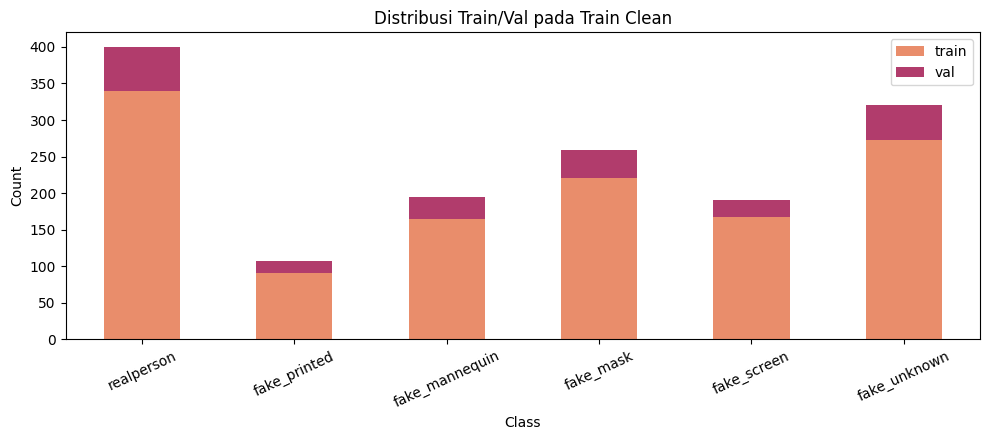

In [ ]:
split_plot_df = pd.DataFrame({
    'train': [sum(1 for _, i in tr_pairs if i == idx) for idx in range(CFG.N_CLASSES)],
    'val':   [sum(1 for _, i in va_pairs if i == idx) for idx in range(CFG.N_CLASSES)],
}, index=CFG.CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 4.5))
split_plot_df.plot(kind='bar', stacked=True, ax=ax, color=[EDA_PALETTE[0], EDA_PALETTE[3]])
ax.set_title('Distribusi Train/Val pada Train Clean')
ax.set_ylabel('Count')
ax.set_xlabel('Class')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

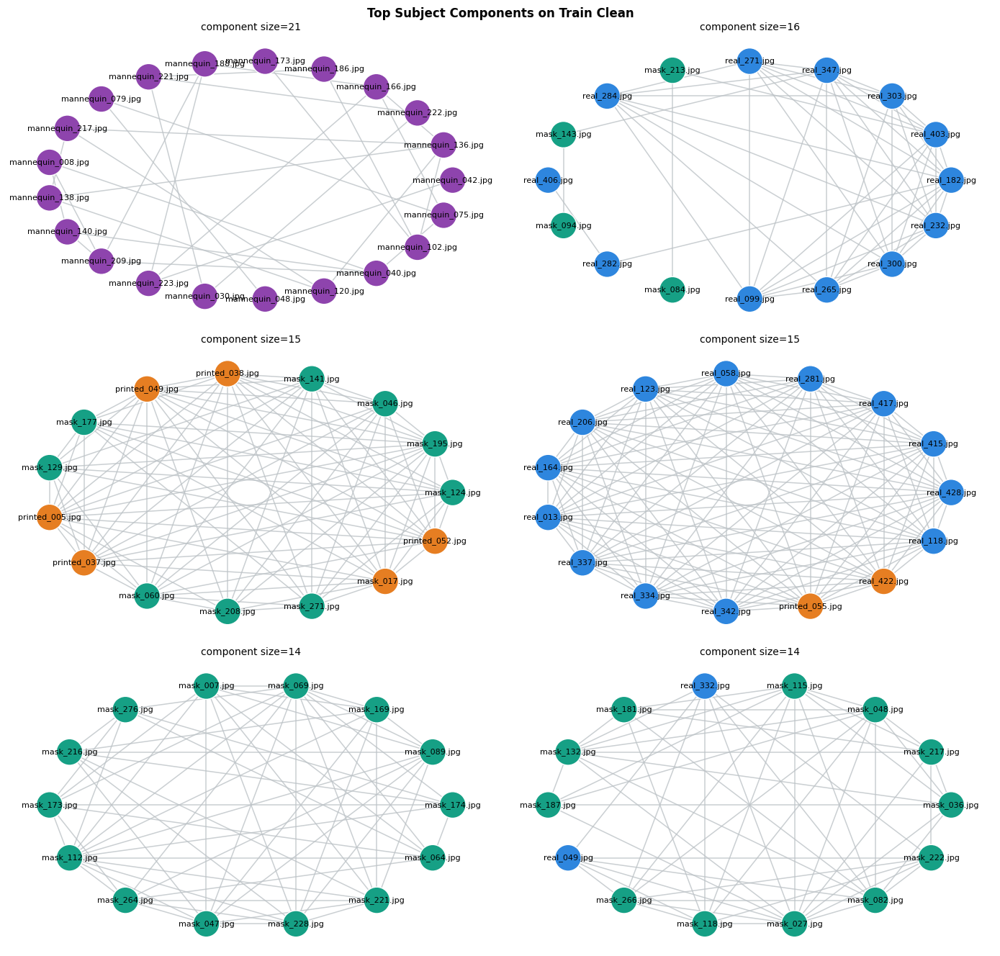

In [ ]:
def plot_top_subject_components(graph, fname_to_cls, top_n=6):
    comps = [sorted(c) for c in nx.connected_components(graph) if len(c) > 1]
    if not comps:
        print('No multi-member components to plot.')
        return
    comps = sorted(comps, key=lambda c: (-len(c), c))[:top_n]
    ncols = 2 if len(comps) > 1 else 1
    nrows = int(np.ceil(len(comps) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, max(4.5, nrows * 4.5)))
    axes = np.atleast_1d(axes).reshape(-1)
    for ax, comp in zip(axes, comps):
        sub = graph.subgraph(comp).copy()
        pos = nx.circular_layout(sub)
        node_colors = [SHA256_COLORS.get(fname_to_cls.get(node, ''), SHA256_COLORS.get('fake_unknown', '#7f8c8d')) for node in sub.nodes()]
        labels = {node: node[:18] for node in sub.nodes()}
        nx.draw_networkx_edges(sub, pos, ax=ax, edge_color='#bdc3c7', width=1.1, alpha=0.8)
        nx.draw_networkx_nodes(sub, pos, ax=ax, node_color=node_colors, node_size=700, edgecolors='white', linewidths=1.0)
        nx.draw_networkx_labels(sub, pos, labels=labels, font_size=8, ax=ax)
        ax.set_title(f'component size={len(comp)}', fontsize=10)
        ax.axis('off')
    for ax in axes[len(comps):]:
        ax.axis('off')
    fig.suptitle('Top Subject Components on Train Clean', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

_fname_to_cls = {p.name: CFG.CLASS_NAMES[i] for p, i in train_pairs}
_G_train = _G.subgraph(set(_fnames)).copy()
plot_top_subject_components(_G_train, _fname_to_cls)

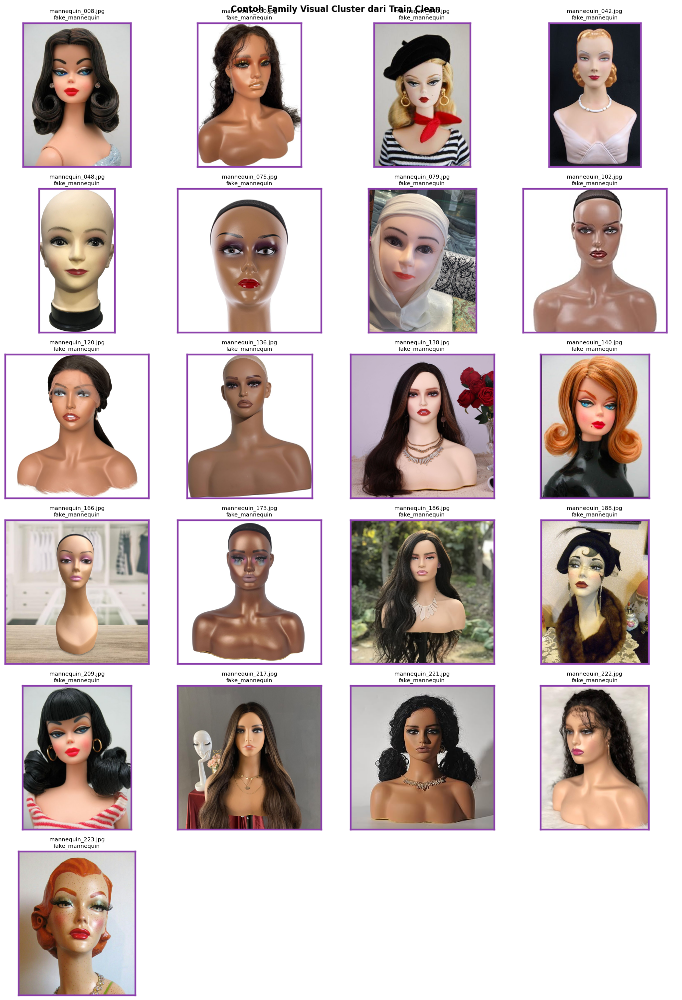

In [ ]:
_clean_path_map = {p.name: p for p, _ in train_pairs}
_largest_comp = next((sorted(c) for c in sorted(nx.connected_components(_G_train), key=lambda c: (-len(c), sorted(c))) if len(c) > 1), [])
if not _largest_comp:
    print('No multi-member component available.')
else:
    ncols = 4
    nrows = int(np.ceil(len(_largest_comp) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, max(4.5, nrows * 3.4)))
    axes = np.atleast_1d(axes).reshape(-1)
    for ax, fname in zip(axes, _largest_comp):
        img = load_rgb_image(_clean_path_map[fname])
        cls = _fname_to_cls.get(fname, '')
        ax.imshow(img)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(2.5)
            spine.set_edgecolor(SHA256_COLORS.get(cls, SHA256_COLORS.get('fake_unknown', '#7f8c8d')))
        ax.set_title(f'{fname}\n{cls}', fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
    for ax in axes[len(_largest_comp):]:
        ax.axis('off')
    fig.suptitle('Contoh Family Visual Cluster dari Train Clean', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pemodelan <a name="6"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Arsitektur yang digunakan menggabungkan *backbone* DINOv3 yang dibekukan (*frozen*) dengan *head* klasifikasi yang dapat dilatih. Pendekatan ini memanfaatkan representasi fitur berkualitas tinggi yang sudah dipelajari DINOv3 dari 1,689 miliar gambar, sekaligus menjaga efisiensi komputasi karena hanya sebagian kecil parameter yang diperbarui.

## Arsitektur Model

Token CLS merangkum representasi global wajah, sementara rata-rata *patch token* menangkap detail tekstur permukaan yang membedakan setiap kelas serangan. Keduanya digabungkan sebelum dimasukkan ke *head* klasifikasi.

V4 membuka 3 blok *transformer* terakhir *backbone* untuk *fine-tuning* parsial. Lapisan sebelumnya tetap *frozen* agar representasi fitur umum tidak terdegradasi. Dua kelompok *learning rate* digunakan: `BACKBONE_LR=1e-5` untuk blok yang dibuka dan `HEAD_LR=3e-4` untuk *head* klasifikasi.

Perlu diperhatikan bahwa model DINOv3 menyertakan 4 *register token* yang diletakkan setelah token CLS. Saat membaca `last_hidden_state`, indeks 0 adalah CLS, indeks 1-4 adalah *register token*, dan indeks 5 ke atas adalah *patch token*.

In [ ]:
class DINOv3Classifier(nn.Module):
    def __init__(self, model_name: str, embed_dim: int, num_classes: int,
                 dropout: float = 0.3, attn_impl: str = 'sdpa'):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(
            model_name, attn_implementation=attn_impl
        )
        # Freeze entire backbone
        for param in self.backbone.parameters():
            param.requires_grad = False
        # V4: unfreeze last 3 blocks -- disabled in V6 (fully frozen)
        # _blocks = self.backbone.model.layer
        # _n_blocks = len(_blocks)
        # for i, block in enumerate(_blocks):
        #     if i >= _n_blocks - 3:
        #         for p in block.parameters():
        #             p.requires_grad = True
        # Read register token count from model config (ViT-H+: 4)
        self._n_reg = self.backbone.config.num_register_tokens

        self.head = nn.Sequential(
            nn.Linear(embed_dim * 2, 512),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, pixel_values):
        out   = self.backbone(pixel_values=pixel_values)
        hs    = out.last_hidden_state              # [B, 1+n_reg+N, D]
        cls   = hs[:, 0]                           # CLS token
        patch = hs[:, 1 + self._n_reg:].mean(dim=1)  # mean patch tokens
        feat  = torch.cat([cls, patch], dim=1)     # [B, 2*D]
        return self.head(feat)


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = DINOv3Classifier(
    model_name=CFG.MODEL_NAME,
    embed_dim=CFG.EMBED_DIM,
    num_classes=CFG.N_CLASSES,
    dropout=CFG.DROPOUT,
    attn_impl=CFG.TRAIN_ATTN_IMPL,
).to(DEVICE)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f'Parameter terlatih : {trainable:,} / {total:,} ({trainable/total*100:.2f}%)')
print(f'Backend attention   : {CFG.TRAIN_ATTN_IMPL}')
# Sanity: backbone must be fully frozen
_frozen   = sum(1 for p in model.backbone.parameters() if not p.requires_grad)
_unfrozen = sum(1 for p in model.backbone.parameters() if p.requires_grad)
assert _unfrozen == 0, f'Expected 0 unfrozen backbone params, got {_unfrozen}'
print(f'Backbone: fully frozen ({_frozen} params)')

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.36G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/615 [00:00<?, ?it/s]

Parameter terlatih : 1,314,310 / 841,906,950 (0.16%)
Backend attention   : sdpa
Backbone: fully frozen (615 params)


---

## Inspeksi Arsitektur Backbone

Sel ini mencetak struktur modul *backbone* untuk memverifikasi jalur atribut yang digunakan pada *partial fine-tuning* dan XAI.

In [ ]:
print('=== backbone named_children ===')
for _n, _m in model.backbone.named_children():
    print(f'  {_n}: {type(_m).__name__}')

print()
print('=== last block (model.backbone.model.layer[-1]) ===')
_last_block = model.backbone.model.layer[-1]
print(type(_last_block).__name__)
for _n, _m in _last_block.named_modules():
    if _n != '':
        print(f'  {_n}: {type(_m).__name__}')

=== backbone named_children ===
  embeddings: DINOv3ViTEmbeddings
  rope_embeddings: DINOv3ViTRopePositionEmbedding
  model: DINOv3ViTEncoder
  norm: LayerNorm

=== last block (model.backbone.model.layer[-1]) ===
DINOv3ViTLayer
  norm1: LayerNorm
  attention: DINOv3ViTAttention
  attention.k_proj: Linear
  attention.v_proj: Linear
  attention.q_proj: Linear
  attention.o_proj: Linear
  layer_scale1: DINOv3ViTLayerScale
  drop_path: Identity
  norm2: LayerNorm
  mlp: DINOv3ViTGatedMLP
  mlp.gate_proj: Linear
  mlp.up_proj: Linear
  mlp.down_proj: Linear
  mlp.act_fn: SiLUActivation
  layer_scale2: DINOv3ViTLayerScale


---

## Metrik

Metrik utama yang digunakan adalah *macro F1-score*, yang memberikan bobot setara pada setiap kelas terlepas dari jumlah sampelnya. Ini penting mengingat potensi ketidakseimbangan kelas pada dataset serangan presentasi.

In [ ]:
def compute_f1(preds, targets, average='macro'):
    return f1_score(targets, preds, average=average, zero_division=0)

def macro_f1(preds, targets):
    return compute_f1(preds, targets, average='macro')

---

## Utilitas Pelatihan

### EarlyStopping dan Simpan Checkpoint

In [ ]:
class EarlyStopping:
    def __init__(self, patience: int):
        self.patience    = patience
        self.best_metric = -1.0
        self.best_train_metric = -1.0
        self.counter     = 0
        self.should_stop = False
        self.best_state  = None

    def step(self, metric, train_metric, model):
        improved = (metric, train_metric) > (self.best_metric, self.best_train_metric)
        if improved:
            self.best_metric = metric
            self.best_train_metric = train_metric
            self.counter     = 0
            self.best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            return True
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False


def save_checkpoint(model, optimizer, epoch, metric, train_metric, path):
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'metric': metric,
        'train_metric': train_metric,
    }, path)
    print(
        f'  Checkpoint disimpan: epoch {epoch}  '
        f'val_F1={metric:.4f}  train_F1={train_metric:.4f} -> {path.name}'
    )

### Scheduler: Polynomial LR dengan Warmup

*Scheduler* dengan *linear warmup* diikuti *polynomial decay* menstabilkan gradien di awal pelatihan ketika parameter *head* masih jauh dari optimal, kemudian menurunkan *learning rate* secara bertahap menuju akhir pelatihan.

In [ ]:
class PolynomialLRWithWarmup:
    def __init__(self, optimizer, warmup_steps, total_steps, poly_power=0.9):
        self.optimizer    = optimizer
        self.warmup_steps = warmup_steps
        self.total_steps  = total_steps
        self.poly_power   = poly_power
        self.current_step = 0
        self.base_lrs     = [pg['lr'] for pg in optimizer.param_groups]

    def step(self):
        self.current_step += 1
        s = self.current_step
        if s <= self.warmup_steps:
            scale = s / max(1, self.warmup_steps)
        else:
            progress = (s - self.warmup_steps) / max(1, self.total_steps - self.warmup_steps)
            scale    = max(0.0, (1.0 - progress) ** self.poly_power)
        for pg, base_lr in zip(self.optimizer.param_groups, self.base_lrs):
            pg['lr'] = base_lr * scale

### `train_one_epoch`

In [ ]:
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device,
                    criterion, accum_steps=1):
    model.train()
    total_loss, all_preds, all_labels = 0.0, [], []
    optimizer.zero_grad()

    for step, (imgs, labels) in enumerate(
        tqdm(loader, desc='  Train', leave=True)
    ):
        imgs, labels = imgs.to(device), labels.to(device)
        with autocast(device_type=device.type, enabled=CFG.USE_AMP):
            logits = model(imgs)
            loss   = criterion(logits, labels)
            loss   = loss / accum_steps

        scaler.scale(loss).backward()

        if (step + 1) % accum_steps == 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad()

        total_loss += loss.item() * accum_steps
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader)
    f1       = macro_f1(all_preds, all_labels)
    return avg_loss, f1, all_preds, all_labels

### `validate`

In [ ]:
@torch.no_grad()
def validate(model, loader, device, criterion):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []

    for imgs, labels in tqdm(loader, desc='  Val  ', leave=True):
        imgs, labels = imgs.to(device), labels.to(device)
        with autocast(device_type=device.type, enabled=CFG.USE_AMP):
            logits = model(imgs)
            loss   = criterion(logits, labels)
        total_loss += loss.item()
        all_preds.extend(logits.argmax(1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader)
    f1       = macro_f1(all_preds, all_labels)
    return avg_loss, f1, all_preds, all_labels

---

## Optimizer dan Training

In [ ]:
_class_counts = Counter(i for _, i in train_pairs)
_counts = torch.tensor([_class_counts.get(i, 0) for i in range(CFG.N_CLASSES)], dtype=torch.float32)
assert torch.all(_counts > 0), 'Ada kelas kosong pada training set aktif; class weights tidak dapat dihitung aman.'
class_weights = (_counts.sum() / (CFG.N_CLASSES * _counts)).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
# V4: label_smoothing=CFG.LABEL_SMOOTHING -- disabled in V6 (backbone fully frozen)
print('Bobot kelas (inverse-freq):', ', '.join(
    f'{CFG.CLASS_NAMES[i][:8]}={class_weights[i].item():.3f}' for i in range(CFG.N_CLASSES)
))

# V4: Two-LR optimizer (backbone_lr + head_lr) -- disabled in V6 (backbone frozen)
# _backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
# _head_params     = list(model.head.parameters())
# optimizer = torch.optim.AdamW([
#     {'params': _backbone_params, 'lr': CFG.BACKBONE_LR},
#     {'params': _head_params,     'lr': CFG.HEAD_LR},
# ], weight_decay=CFG.WEIGHT_DECAY)
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
print(f'Optimizer: lr={CFG.LR}')
scaler  = GradScaler(device=DEVICE.type, enabled=CFG.USE_AMP)

total_steps   = (len(train_loader) // CFG.GRAD_ACCUM_STEPS) * CFG.EPOCHS
warmup_steps  = total_steps // 10
scheduler     = PolynomialLRWithWarmup(optimizer, warmup_steps, total_steps)
early_stop    = EarlyStopping(patience=CFG.EARLY_STOP_PATIENCE)

print(f'Total steps   : {total_steps}')
print(f'Warmup steps  : {warmup_steps}')

Bobot kelas (inverse-freq): realpers=0.613, fake_pri=2.291, fake_man=1.264, fake_mas=0.947, fake_scr=1.284, fake_unk=0.766
Optimizer: lr=0.0003
Total steps   : 600
Warmup steps  : 60


  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.22s/it]


Epoch   1/15  tr_loss=1.4249  tr_f1=0.8117  va_loss=0.8674  va_f1=0.9935
  train: realpers=0.82  printed=0.68  mannequi=0.85  mask=0.75  screen=0.89  unknown=0.89
  val  : realpers=0.99  printed=0.97  mannequi=1.00  mask=1.00  screen=1.00  unknown=1.00
  Checkpoint disimpan: epoch 1  val_F1=0.9935  train_F1=0.8117 -> dinov3_vith_v17_clean_pipeline_best.pth


  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.22s/it]


Epoch   2/15  tr_loss=0.4256  tr_f1=0.9149  va_loss=0.1712  va_f1=0.9644
  train: realpers=0.89  printed=0.90  mannequi=0.93  mask=0.87  screen=0.95  unknown=0.94
  val  : realpers=0.97  printed=0.91  mannequi=1.00  mask=0.97  screen=0.93  unknown=0.99


  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.17s/it]


...

  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.19s/it]


Epoch  14/15  tr_loss=0.0229  tr_f1=0.9950  va_loss=0.0238  va_f1=1.0000
  train: realpers=0.99  printed=0.99  mannequi=1.00  mask=0.99  screen=1.00  unknown=1.00
  val  : realpers=1.00  printed=1.00  mannequi=1.00  mask=1.00  screen=1.00  unknown=1.00


  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.21s/it]


Epoch  15/15  tr_loss=0.0217  tr_f1=0.9982  va_loss=0.0237  va_f1=1.0000
  train: realpers=1.00  printed=1.00  mannequi=1.00  mask=1.00  screen=1.00  unknown=1.00
  val  : realpers=1.00  printed=1.00  mannequi=1.00  mask=1.00  screen=1.00  unknown=1.00
  Checkpoint disimpan: epoch 15  val_F1=1.0000  train_F1=0.9982 -> dinov3_vith_v17_clean_pipeline_best.pth

=== Misclassified Train Images ===


Total: 3 / 1255 misclassified
  mask_001.jpg                         true=fake_mask             pred=fake_printed
  unknown_009.jpg                      true=fake_unknown          pred=realperson
  unknown_331.jpg                      true=fake_unknown          pred=realperson


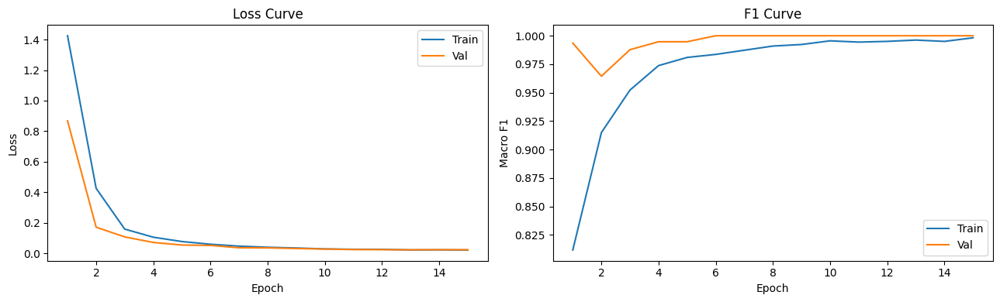

In [ ]:
metrics_log = []
_cls_abbr = [c.replace('fake_', '')[:8] for c in CFG.CLASS_NAMES]

if CFG.RUN_NAME != 'INFERENCE':
    for epoch in range(CFG.EPOCHS):
        tr_loss, tr_f1, tr_preds, tr_labels = train_one_epoch(
            model, train_loader, optimizer, scheduler, scaler, DEVICE,
            criterion, accum_steps=CFG.GRAD_ACCUM_STEPS,
        )
        va_loss, va_f1, va_preds, va_labels = validate(model, val_loader, DEVICE, criterion)

        _tr_pcf1 = f1_score(tr_labels, tr_preds, average=None, zero_division=0)
        _va_pcf1 = f1_score(va_labels, va_preds, average=None, zero_division=0)

        metrics_log.append({
            'epoch': epoch + 1,
            'tr_loss': tr_loss, 'tr_f1': tr_f1,
            'va_loss': va_loss, 'va_f1': va_f1,
        })
        print(
            f'Epoch {epoch+1:3d}/{CFG.EPOCHS}  '
            f'tr_loss={tr_loss:.4f}  tr_f1={tr_f1:.4f}  '
            f'va_loss={va_loss:.4f}  va_f1={va_f1:.4f}'
        )
        print('  train: ' + '  '.join(
            f'{_cls_abbr[i]}={_tr_pcf1[i]:.2f}' for i in range(CFG.N_CLASSES)
        ))
        print('  val  : ' + '  '.join(
            f'{_cls_abbr[i]}={_va_pcf1[i]:.2f}' for i in range(CFG.N_CLASSES)
        ))

        improved = early_stop.step(va_f1, tr_f1, model)
        if improved:
            save_checkpoint(model, optimizer, epoch + 1, va_f1, tr_f1, CFG.CHECKPOINT_PATH)
        if early_stop.should_stop:
            print(f'Early stopping pada epoch {epoch+1}.')
            break

    # -- Misclassified train images (eval pass, no augmentation) ----------
    print('\n=== Misclassified Train Images ===')
    _tr_eval_loader = DataLoader(
        FaceSpoofDataset(tr_pairs, transform=val_transform),
        batch_size=CFG.BATCH_SIZE, shuffle=False,
        num_workers=CFG.NUM_WORKERS, pin_memory=True,
        persistent_workers=CFG.NUM_WORKERS > 0,
    )
    _tr_eval_preds = []
    model.eval()
    with torch.no_grad():
        for _imgs, _ in tqdm(_tr_eval_loader, desc='  Train eval', leave=False):
            with autocast(device_type=DEVICE.type, enabled=CFG.USE_AMP):
                _logits = model(_imgs.to(DEVICE))
            _tr_eval_preds.extend(_logits.argmax(1).cpu().tolist())
    _misclassified_tr = [
        (p.name, CFG.CLASS_NAMES[true_i], CFG.CLASS_NAMES[pred_i])
        for (p, true_i), pred_i in zip(tr_pairs, _tr_eval_preds)
        if true_i != pred_i
    ]
    print(f'Total: {len(_misclassified_tr)} / {len(tr_pairs)} misclassified')
    for _fname, _true, _pred in _misclassified_tr:
        print(f'  {_fname:35s}  true={_true:20s}  pred={_pred}')

    # Kurva pelatihan
    df_log = pd.DataFrame(metrics_log)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ax1.plot(df_log['epoch'], df_log['tr_loss'], label='Train')
    ax1.plot(df_log['epoch'], df_log['va_loss'], label='Val')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
    ax1.set_title('Loss Curve'); ax1.legend()
    ax2.plot(df_log['epoch'], df_log['tr_f1'], label='Train')
    ax2.plot(df_log['epoch'], df_log['va_f1'], label='Val')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Macro F1')
    ax2.set_title('F1 Curve'); ax2.legend()
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / '05_training_curves.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('RUN_NAME=INFERENCE, pelatihan dilewati.')

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Inferensi dan Submisi <a name="7"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Sel-sel berikut memuat *checkpoint* terbaik, mengevaluasi model pada *validation set*, kemudian menjalankan inferensi pada *test set* untuk menghasilkan berkas submisi. Bagian ini dapat dieksekusi secara mandiri dengan mengatur `RUN_NAME = 'INFERENCE'`.

## Muat Checkpoint Terbaik

Apabila *checkpoint* tersedia di Google Drive, berkas dapat diunduh terlebih dahulu menggunakan `gdown` sebelum dimuat ke model. Jika *training* baru saja selesai, *checkpoint* sudah ada di `CFG.OUTPUT_DIR`.

In [ ]:
CKPT_URL = 'https://drive.google.com/uc?id=1x1uN9c0rLjggiBZCmDfjM4HBHuOEYbhU'
if not CFG.CHECKPOINT_PATH.exists():
    gdown.download(CKPT_URL, str(CFG.CHECKPOINT_PATH), quiet=False)


In [ ]:
def load_checkpoint(path, model, optimizer=None):
    ckpt = torch.load(path, map_location='cpu', weights_only=False)
    model.load_state_dict(ckpt['model_state_dict'])
    if optimizer is not None:
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
    print(f'Checkpoint dimuat: epoch {ckpt["epoch"]}  F1={ckpt["metric"]:.4f}')
    return ckpt

if CFG.RUN_NAME == 'INFERENCE':
    model = DINOv3Classifier(
        model_name=CFG.MODEL_NAME,
        embed_dim=CFG.EMBED_DIM,
        num_classes=CFG.N_CLASSES,
        dropout=CFG.DROPOUT,
        attn_impl=CFG.TRAIN_ATTN_IMPL,
    ).to(DEVICE)
    load_checkpoint(CFG.CHECKPOINT_PATH, model)
else:
    print(
        f'Best model already loaded (val F1={early_stop.best_metric:.4f}, '
        f'train F1={early_stop.best_train_metric:.4f})'
    )

Best model already loaded (val F1=1.0000, train F1=0.9982)


---

## Evaluasi Validasi

Laporan klasifikasi dan matriks konfusi memberikan gambaran lengkap tentang performa model per kelas. Kelas dengan *recall* rendah menjadi prioritas perbaikan pada iterasi berikutnya.

In [ ]:
_, val_f1, val_preds, val_labels = validate(model, val_loader, DEVICE, criterion)
print(f'Val Macro F1: {val_f1:.4f}')
print()
print(classification_report(
    val_labels, val_preds, target_names=CFG.CLASS_NAMES, zero_division=0
))

  Val  : 100%|██████████| 7/7 [00:36<00:00,  5.26s/it]

Val Macro F1: 1.0000

                precision    recall  f1-score   support

    realperson       1.00      1.00      1.00        60
  fake_printed       1.00      1.00      1.00        16
fake_mannequin       1.00      1.00      1.00        29
     fake_mask       1.00      1.00      1.00        39
   fake_screen       1.00      1.00      1.00        24
  fake_unknown       1.00      1.00      1.00        48

      accuracy                           1.00       216
     macro avg       1.00      1.00      1.00       216
  weighted avg       1.00      1.00      1.00       216



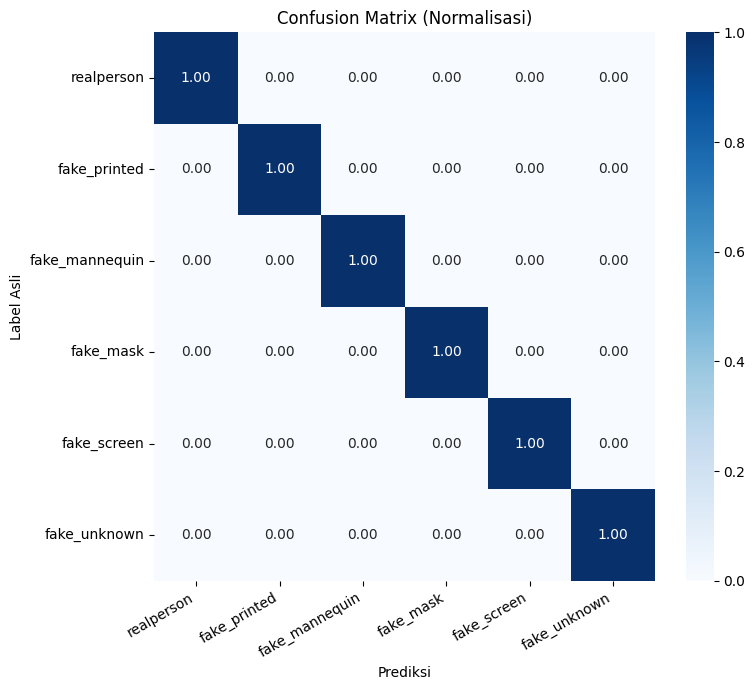

In [ ]:
cm = confusion_matrix(val_labels, val_preds, normalize='true')

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    cm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=CFG.CLASS_NAMES, yticklabels=CFG.CLASS_NAMES,
    ax=ax,
)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Label Asli')
ax.set_title('Confusion Matrix (Normalisasi)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / '06_confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# Misclassified and correct val samples for XAI analysis
val_errors = [
    (va_pairs[i][0], int(val_labels[i]), int(val_preds[i]))
    for i in range(len(va_pairs))
    if val_preds[i] != val_labels[i]
]
# 2 correct samples per class (12 total for 6-class dataset)
_correct_all = [
    (va_pairs[i][0], int(val_labels[i]), int(val_preds[i]))
    for i in range(len(va_pairs))
    if val_preds[i] == val_labels[i]
]
_per_class = defaultdict(list)
for item in _correct_all:
    cls = item[1]
    if len(_per_class[cls]) < 2:
        _per_class[cls].append(item)
# sorted by class index -- each row (n_cols=2) contains the same class
val_correct = [item for cls in sorted(_per_class) for item in _per_class[cls]]
print(f'Misclassified: {len(val_errors)} / {len(va_pairs)} val samples')
for path, true_l, pred_l in val_errors:
    print(f'  {Path(path).name:40s}  true={CFG.CLASS_NAMES[true_l]:15s}  pred={CFG.CLASS_NAMES[pred_l]}')

Misclassified: 0 / 216 val samples


---

## Inferensi Test Set

Inferensi menggunakan **8-view D4 TTA** -- 4 rotasi x 2 flip, logit dirata-ratakan. Inferensi dilakukan pada gambar penuh yang sudah melalui `Resize` dan normalisasi yang sama dengan validasi.

In [ ]:
class TestDataset(Dataset):
    """Accepts preloaded (pil_image, img_id) pairs for inference."""
    def __init__(self, items, transform):
        self.items     = items      # list of (PIL.Image, str)
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        img, img_id = self.items[idx]
        return self.transform(img), img_id


In [ ]:
print('Building test items (full image)...')
_test_items = []
for p in tqdm(test_images, desc='Test set'):
    img = load_rgb_image(p)
    _test_items.append((img, p.stem))
print(f'Done. {len(_test_items)} test images loaded.')


Building test items (full image)...


Test set: 100%|██████████| 404/404 [00:15<00:00, 26.75it/s]

Done. 404 test images loaded.


In [ ]:
# TTA: 8 D4 orientations (4 rotations Ã— 2 flip states)
_TTA_CONFIGS = [
    (0,   False),
    (90,  False),
    (180, False),
    (270, False),
    (0,   True),
    (90,  True),
    (180, True),
    (270, True),
]

def _apply_tta(imgs, angle, hflip):
    if angle > 0:
        imgs = v2.functional.rotate(imgs, angle)
    if hflip:
        imgs = v2.functional.horizontal_flip(imgs)
    return imgs


In [ ]:
test_dataset = TestDataset(_test_items, val_transform)
test_loader  = DataLoader(
    test_dataset, batch_size=CFG.BATCH_SIZE,
    shuffle=False, num_workers=CFG.NUM_WORKERS, pin_memory=True,
    persistent_workers=CFG.NUM_WORKERS > 0,
)

model.eval()
all_ids     = []
tta_logits  = None

for view_idx, (angle, hflip) in enumerate(
    tqdm(_TTA_CONFIGS, desc='TTA views')
):
    view_logits = []
    with torch.no_grad():
        for imgs, ids in test_loader:
            imgs = _apply_tta(imgs.to(DEVICE), angle, hflip)
            with autocast(device_type=DEVICE.type, enabled=CFG.USE_AMP):
                logits = model(imgs)
            view_logits.append(logits.cpu())
            if view_idx == 0:
                all_ids.extend(ids)
    view_logits = torch.cat(view_logits, dim=0)
    tta_logits  = view_logits if tta_logits is None else tta_logits + view_logits

tta_logits /= len(_TTA_CONFIGS)
all_preds = [CFG.CLASS_NAMES[i] for i in tta_logits.argmax(1).tolist()]
print(f'TTA selesai: {len(all_preds)} gambar, {len(_TTA_CONFIGS)} views')

TTA views: 100%|██████████| 8/8 [09:04<00:00, 68.08s/it]

TTA selesai: 404 gambar, 8 views


---

## Pembuatan Berkas Submisi

Submisi akhir ditulis langsung dari prediksi model pada *test set* yang sudah diproses.

In [ ]:
df_sub = pd.DataFrame({'id': all_ids, 'label': all_preds})
df_sub = df_sub.sort_values('id').reset_index(drop=True)

assert not df_sub[['id', 'label']].isna().any().any(), 'Terdapat nilai kosong pada submisi'
assert df_sub['label'].isin(CFG.CLASS_NAMES).all(), 'Label tidak valid'

df_sub.to_csv(CFG.SUBMISSION_CSV, index=False)
print(f'Submisi disimpan ke {CFG.SUBMISSION_CSV}')
print(f'Bentuk: {df_sub[["id", "label"]].shape}')
print(df_sub['label'].value_counts())

Submisi disimpan ke /kaggle/working/dinov3-vith16plus/dinov3_vith_v17_clean_pipeline/submission_dinov3_vith_v17_clean_pipeline.csv
Bentuk: (404, 2)
label
realperson        101
fake_screen        72
fake_mask          72
fake_printed       59
fake_mannequin     51
fake_unknown       49
Name: count, dtype: int64


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Pasca-Analisis <a name="8"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

## Analisis Kesalahan dan Visualisasi Perhatian (XAI)

Sampel validasi yang salah diklasifikasikan ditampilkan bersama *heatmap* perhatian DINOv3 dari lapisan *transformer* terakhir. Label asli dan prediksi model ditampilkan di atas setiap pasang gambar. Analisis ini memperlihatkan pola kegagalan model: apakah perhatian jatuh pada tekstur yang tepat namun prediksinya tetap salah, atau model memang berfokus pada area yang tidak relevan seperti latar belakang atau artefak pencahayaan.

`get_attention_map` mengekstraksi peta perhatian dari lapisan *transformer* terakhir DINOv3 menggunakan *forward hook*. `DINOv3ViTLayer` membuang bobot perhatian (`attn_weights`) pada *forward pass* standar, sehingga `output_attentions` tidak tersedia. Untuk menjaga training tetap cepat, bagian ini memuat ulang model kecil khusus XAI dengan backend attention `eager`. *Hook* ditempatkan pada modul `DINOv3ViTAttention` terakhir untuk menangkap `attn_weights` sebelum dibuang. Fungsi mengembalikan heatmap `[H_grid, W_grid]` yang merepresentasikan seberapa besar token CLS memperhatikan tiap *patch*.

Loading weights:   0%|          | 0/615 [00:00<?, ?it/s]

XAI attention backend: eager


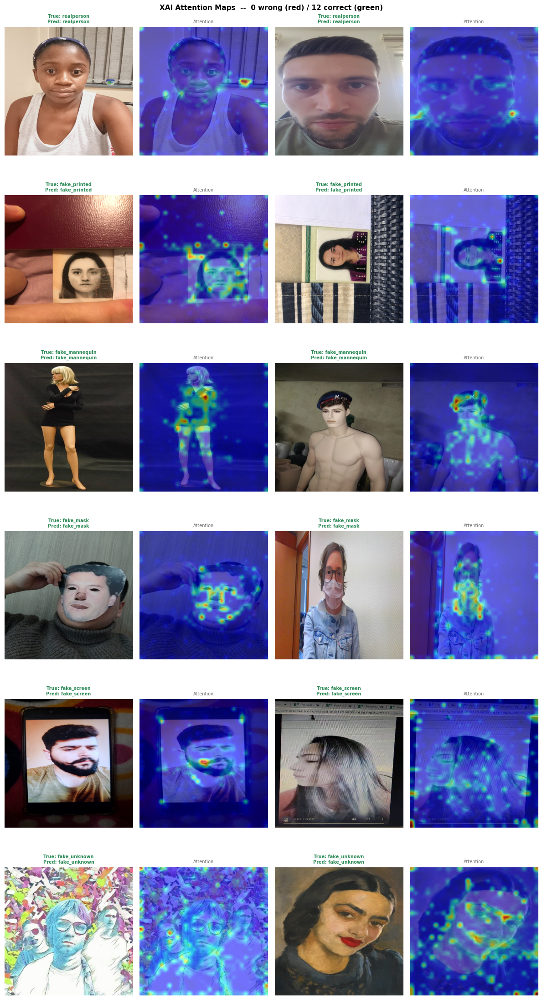

In [ ]:
xai_model = DINOv3Classifier(
    model_name=CFG.MODEL_NAME,
    embed_dim=CFG.EMBED_DIM,
    num_classes=CFG.N_CLASSES,
    dropout=CFG.DROPOUT,
    attn_impl=CFG.XAI_ATTN_IMPL,
).to(DEVICE)
if CFG.RUN_NAME == 'INFERENCE' or not hasattr(early_stop, 'best_state'):
    load_checkpoint(CFG.CHECKPOINT_PATH, xai_model)
else:
    xai_model.load_state_dict(early_stop.best_state)
xai_model.eval()
print(f'XAI attention backend: {CFG.XAI_ATTN_IMPL}')

def get_attention_map(model, img_tensor):
    attn_store = {}

    def _hook(module, inp, out):
        # DINOv3ViTAttention with eager backend returns (context, attn_weights)
        attn_store['w'] = out[1]

    hook = model.backbone.model.layer[-1].attention.register_forward_hook(_hook)
    with torch.no_grad():
        model.backbone(pixel_values=img_tensor.unsqueeze(0).to(DEVICE),
                       output_attentions=True)
    hook.remove()
    attn = attn_store['w'][0]              # [num_heads, seq_len, seq_len]
    n_reg = model.backbone.config.num_register_tokens
    attn_cls = attn.mean(0)[0, 1 + n_reg:]  # avg heads, CLS row, patch cols
    n_side = int(attn_cls.shape[0] ** 0.5)
    return attn_cls.reshape(n_side, n_side).cpu().float().numpy()


def show_error_analysis(model, errors, corrects, class_names, n_wrong=4, n_correct=4):
    wrong  = errors[:n_wrong]
    right  = corrects[:n_correct]
    n_cols = 2
    wrong_rows   = math.ceil(len(wrong)  / n_cols)
    correct_rows = math.ceil(len(right)  / n_cols)
    n_rows = wrong_rows + correct_rows
    if n_rows == 0:
        print('No samples to display.')
        return
    fig, axes = plt.subplots(n_rows, n_cols * 2,
                             figsize=(n_cols * 2 * 3, n_rows * 3.8))
    if n_rows == 1:
        axes = axes[np.newaxis, :]
    val_tf = v2.Compose([
        v2.ToImage(), v2.Resize(CFG.IMG_SIZE, antialias=True),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(CFG.IMAGENET_MEAN, CFG.IMAGENET_STD),
    ])
    def _render_section(samples, start_row, title_color, section_label):
        for idx, (path, true_l, pred_l) in enumerate(samples):
            row, col = divmod(idx, n_cols)
            row += start_row
            img = load_rgb_image(path)
            img_resized = img.resize(CFG.IMG_SIZE)
            tensor = val_tf(img)
            heatmap = get_attention_map(model, tensor)
            heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)
            heatmap = heatmap ** 0.4
            h_up = cv2.resize(heatmap, CFG.IMG_SIZE, interpolation=cv2.INTER_LINEAR)
            heat_rgb = (plt.cm.jet(h_up)[:, :, :3] * 255).astype('uint8')
            overlay = (0.45 * np.array(img_resized) + 0.55 * heat_rgb).astype('uint8')
            ax_orig = axes[row, col * 2]
            ax_orig.imshow(img_resized)
            ax_orig.set_title(
                f'True: {class_names[true_l]}\nPred: {class_names[pred_l]}',
                fontsize=7, color=title_color, fontweight='bold',
            )
            ax_orig.axis('off')
            ax_heat = axes[row, col * 2 + 1]
            ax_heat.imshow(overlay)
            ax_heat.set_title('Attention', fontsize=7, color='dimgray')
            ax_heat.axis('off')
        # blank unused slots in last row of section
        last_row = start_row + math.ceil(len(samples) / n_cols) - 1
        for col in range(len(samples) % n_cols or n_cols, n_cols):
            axes[last_row, col * 2].axis('off'); axes[last_row, col * 2 + 1].axis('off')
        # section label on first row of section
        axes[start_row, 0].set_ylabel(section_label, fontsize=9, color=title_color,
                                      fontweight='bold', rotation=90, labelpad=6)
    _render_section(wrong, 0,          'crimson',  'Wrong')
    _render_section(right, wrong_rows, 'seagreen', 'Correct')
    fig.suptitle(
        f'XAI Attention Maps  --  {len(wrong)} wrong (red) / {len(right)} correct (green)',
        fontsize=11, fontweight='bold',
    )
    plt.tight_layout()
    plt.savefig(CFG.OUTPUT_DIR / '07_attention_maps.png', dpi=100, bbox_inches='tight')
    plt.show()


show_error_analysis(xai_model, val_errors, val_correct, CFG.CLASS_NAMES,
                    n_wrong=4, n_correct=12)

> ### Insights
> Perhatikan apakah *heatmap* pada sampel yang salah berfokus pada area yang seharusnya > membedakan kelas -- misalnya tekstur kulit untuk `realperson` atau pola *halftone* untuk > `fake_printed`. Jika perhatian justru jatuh di latar belakang atau tepi bingkai, > model belum menangkap sinyal diskriminatif yang benar. > Pola kesalahan yang berulang pada pasangan kelas tertentu (misalnya `fake_mask` > diprediksi sebagai `realperson`) mengindikasikan bahwa fitur *backbone* yang dibekukan > tidak cukup untuk memisahkan kelas tersebut -- sinyal untuk *partial fine-tuning* (V1).

### Kelebihan Pendekatan

Pendekatan *frozen* DINOv3 membatasi komputasi pada *head* saja, sehingga total waktu pelatihan jauh lebih singkat dibandingkan *fine-tuning* penuh. Ruang fitur DINOv3 yang mencakup berbagai tekstur permukaan memungkinkan *head* membedakan kulit asli dari silikon atau kertas cetak tanpa menyentuh bobot *backbone*. Gabungan token CLS dan rata-rata *patch token* memberikan sinyal global maupun lokal dalam satu representasi yang kompak.

---

### Keterbatasan yang Diketahui

*Fine-tuning* parsial mengurangi risiko *catastrophic forgetting* tetapi tidak menghilangkannya. Tiga blok terakhir yang dibuka mungkin terlalu sedikit untuk kasus masker hiper-realistis (test_094, test_173) yang membutuhkan fitur domain sangat spesifik. InsightFace juga dapat gagal mendeteksi wajah pada gambar yang sangat kecil, miring ekstrem, atau tertutup, sehingga kualitas *subject-disjoint split* tetap dibatasi oleh kualitas embedding.

---

### Arah Pengembangan Berikutnya

Jika V4 masih kurang pada `fake_mask` vs `realperson`, langkah berikutnya adalah membuka lebih banyak blok (5-6 dari 32) atau menambah epoch dengan LR lebih kecil. Ensemble beberapa *backbone* (ViT-H+ dan ConvNeXt-L) dapat meningkatkan robustitas karena kedua arsitektur menangkap sinyal tekstur dengan mekanisme berbeda.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Pustaka <a name="9"></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

Darcet, T., Oquab, M., Mairal, J., & Bojanowski, P. (2024). *Vision Transformers Need Registers*. ICLR 2024. arXiv:2309.16588.

Oquab, M., Darcet, T., Moutakanni, T., Vo, H. V., Szafraniec, M., Khalidov, V., Fernandez, P., Haziza, D., Massa, F., El-Nouby, A., Assran, M., Ballas, N., Galuba, W., Howes, R., Huang, P.-Y., Li, S.-W., Misra, I., Rabbat, M., Sharma, V., Synnaeve, G., Xu, H., Jegou, H., Mairal, J., Labatut, P., Joulin, A., & Bojanowski, P. (2024). *DINOv2: Learning Robust Visual Features without Supervision*. TMLR. arXiv:2304.07193.

Simeoni, O., Vo, H. V., Seitzer, M., Baldassarre, F., Oquab, M., Jose, C., Khalidov, V., Szafraniec, M., Yi, S., Ramamonjisoa, M., Massa, F., Haziza, D., Wehrstedt, L., Wang, J., Darcet, T., Moutakanni, T., Sentana, L., Roberts, C., Vedaldi, A., Tolan, J., Brandt, J., Couprie, C., Mairal, J., Jegou, H., Labatut, P., & Bojanowski, P. (2025). *DINOv3*. arXiv:2508.10104.

Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., Drame, M., Lhoest, Q., & Rush, A. M. (2020). *Transformers: State-of-the-Art Natural Language Processing*. EMNLP 2020. arXiv:1910.03771.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Thanks! <a name=""></a>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

**Terima kasih khusus kepada:**

Panitia kompetisi **DAC FindIT! 2026** yang telah menyediakan dataset dan platform kompetisi yang menantang.